# IF25-40305 Sistem Teknologi Multimedia — Tugas 2 (Individu)
## Analisis Sinyal Suara & Noise Statis: Representasi 4 Dimensi, Resampling, dan Pembuktian Aliasing

**Institut Teknologi Sumatera (ITERA) — Program Studi Informatika**
*Minggu 03 — Semester Ganjil 2026/2027*

| | |
|---|---|
| **Nama** | Muhammad Fajri Firdaus |
| **NIM** | 123140050 |
| **Mata Kuliah** | IF25-40305 Sistem Teknologi Multimedia |
| **Tugas** | Tugas 2 (Individu) — Analisis Sinyal Suara & Noise Statis |
| **Materi acuan** | Hands-on 1 (`1_audio_resampling.ipynb`) & Hands-on 2 (`2_audio_visual_representation.ipynb`) |

---

### Kondisi perekaman

| Aspek | Keterangan |
|---|---|
| **Sumber noise statis** | Kipas angin listrik yang berputar konstan sepanjang perekaman |
| **Posisi** | Pembaca berada ±0,5–1 meter tepat di depan kipas |
| **Perangkat perekam** | Mikrofon *smartphone* Android |
| **Bahan bacaan** | Beberapa kalimat artikel berita nasional dari portal **detikcom** |
| **Format mentah** | AAC 48 kHz stereo (bawaan perekam), dikonversi ke **WAV PCM 16-bit** tanpa kompresi |
| **Durasi akhir** | ±19,5 detik (dipotong tepat di jeda antar kalimat, masuk rentang 10–20 detik) |

Berkas `audio_original.wav` pada folder ini adalah hasil konversi tersebut. Dua perlakuan yang
dikenakan sebelum analisis hanyalah: (1) membuang 8.179 sampel bernilai nol murni di awal berkas
yang merupakan artefak *encoder* AAC — sampel nol membuat perhitungan $20\log_{10}(0)$ tidak
terdefinisi pada grafik dBFS; dan (2) memotong ujung rekaman pada detik 19,68 yang jatuh tepat di
tengah jeda antar kalimat. **Tidak ada normalisasi, penguatan, maupun filter apa pun** yang
diterapkan, sehingga tingkat derau kipas pada berkas ini masih otentik.

---

### Apa yang dikerjakan di notebook ini

| Bagian | Isi | Acuan |
|---|---|---|
| **§1** | Persiapan pustaka dan konvensi visual | — |
| **§2** | Akuisisi audio, ekstraksi metadata, dan **uji kuantitatif kestasioneran derau** | Hands-on 2 |
| **§3** | Representasi 4 dimensi: Waveform, Spektrum FFT dBFS, Spektrogram STFT, Mel-Spektrogram | Hands-on 2 |
| **§4** | Resampling 48 kHz → 8 kHz: desimasi naif vs resampling berfilter, beserta pembuktian aliasing | Hands-on 1 |
| **§5** | Rangkuman temuan | — |

> **Catatan kejujuran akademik.** Seluruh kode di notebook ini saya tulis dan pahami sendiri
> baris per baris, dengan AI dipakai sebatas asisten diskusi dan pencari sintaks sebagaimana
> diizinkan pada ketentuan tugas. Setiap sel kode diberi komentar alur logika, dan setiap grafik
> diikuti sel Markdown interpretasi dengan bahasa sendiri. Angka-angka yang dikutip di dalam
> narasi seluruhnya berasal dari keluaran sel kode di atasnya — tidak ada nilai yang ditulis
> manual tanpa perhitungan.

## §1. Persiapan Pustaka & Konvensi Visual

Pustaka yang dipakai sama dengan kedua notebook hands-on agar hasilnya sebanding:

- `numpy` — manipulasi array sinyal dan transformasi Fourier (`np.fft.rfft`).
- `scipy.signal` — jendela Hann terkalibrasi (`get_window`), resampling polyphase
  (`resample_poly`), pencarian puncak spektrum (`find_peaks`), dan sintesis *chirp*.
- `librosa` + `librosa.display` — STFT, Mel-spektrogram, *filterbank* Mel, dan penggambaran
  spektrogram berskala waktu-frekuensi.
- `soundfile` — membaca/menulis WAV PCM dan membaca metadata berkas.
- `IPython.display` — pemutar audio di dalam notebook.

Palet warna dan gaya grafik sengaja saya samakan dengan Modul 02 supaya satu konsep selalu
diwakili satu warna yang sama di seluruh gambar.

In [1]:
import os
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import get_window, find_peaks, resample_poly, chirp
import librosa
import librosa.display
import soundfile as sf
import IPython.display as ipd
from IPython.display import display

# tqdm memperingatkan bahwa ipywidgets tidak terpasang sehingga bilah kemajuan
# tidak bisa interaktif. Murni kosmetik, tidak berhubungan dengan analisis, dan
# hanya mengotori keluaran serta hasil cetak PDF - jadi dibisukan.
warnings.filterwarnings('ignore', message='IProgress not found')

# Konfigurasi visualisasi: tajam namun tidak membuat berkas notebook membengkak.
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 110

# Palet warna konsisten, mengikuti konvensi Modul 02.
C_SIGNAL  = '#0284c7'   # biru   - sinyal utama / hasil yang benar
C_ALT     = '#0ea5e9'   # langit - sinyal pembanding
C_NEUTRAL = '#334155'   # slate  - audio mentah, teks netral
C_ALERT   = '#dc2626'   # merah  - cacat, batas bahaya, aliasing
C_GOOD    = '#059669'   # hijau  - kondisi benar / target
C_ACCENT  = '#7c3aed'   # violet - sorotan tersier
C_GOLD    = '#c5a059'   # emas   - panel Mel

# Pemutar audio dibatasi beberapa detik pertama saja: cukup untuk mendengar perbedaan,
# sekaligus menjaga ukuran berkas .ipynb tetap wajar ketika disimpan lengkap dengan outputnya.
PREVIEW_S = 4.0


def putar(sig, sr, label, normalisasi=False):
    """Menampilkan pemutar audio untuk beberapa detik pertama sinyal.

    normalisasi=False dipakai sebagai default supaya perbandingan kenyaringan antar
    sinyal tetap jujur (skala amplitudo aslinya tidak diubah oleh pemutar).
    """
    print(label)
    display(ipd.Audio(sig[:int(PREVIEW_S * sr)], rate=sr, normalize=normalisasi))


print(f"numpy      : {np.__version__}")
print(f"librosa    : {librosa.__version__}")
print(f"soundfile  : {sf.__version__}")
print("\nSeluruh pustaka analisis audio berhasil dimuat.")

numpy      : 2.5.3
librosa    : 1.0.0
soundfile  : 0.14.0

Seluruh pustaka analisis audio berhasil dimuat.


## §2. Akuisisi Audio & Metadata

### 2.1 Mengapa harus noise *statis*?

**Noise statis** (*stationary noise*) adalah derau yang sifat statistiknya — rata-rata amplitudo,
daya, variansi, dan sebaran spektrumnya — praktis tidak berubah dari detik ke detik. Deru kipas
angin termasuk kategori ini karena baling-balingnya berputar pada kecepatan tetap, sehingga
menghasilkan dua komponen sekaligus:

1. **Komponen tonal periodik** — dengung pada frekuensi *blade passing* (jumlah bilah × putaran
   per detik) beserta harmonik kelipatannya.
2. **Komponen broadband** — desis akibat turbulensi udara, tersebar merata di frekuensi tinggi.

Konsekuensi visualnya: pada spektrogram, derau statis tampak sebagai **pita horizontal yang tidak
pernah padam** dari awal sampai akhir rekaman. Pola ini kontras dengan suara pembacaan berita yang
harmoniknya naik-turun mengikuti intonasi. Derau *non*-statis (klakson, ketukan pintu, gonggongan)
justru akan tampak sebagai paku vertikal mendadak dan sengaja dihindari saat merekam.

### 2.2 Membaca berkas dan metadatanya

Dua cara pembacaan dipakai bersamaan karena keduanya memberi informasi berbeda:

- `soundfile.info()` — membaca **metadata kontainer** apa adanya: format, kedalaman bit, jumlah
  kanal, dan laju sampel. Ini yang membuktikan berkas benar-benar WAV PCM *uncompressed*.
- `librosa.load(..., sr=None)` — membaca **data sampelnya**. Argumen `sr=None` wajib ada; tanpa
  itu librosa akan diam-diam me-*resample* ke 22.050 Hz sehingga laju sampel asli hilang, dan
  seluruh analisis aliasing di §4 menjadi tidak sahih.

In [2]:
# Pencarian berkas defensif: notebook tetap berjalan baik dari dalam folder tugas
# maupun dari root repositori.
kandidat_path = [
    'audio_original.wav',
    '02_audio_noise_statis/audio_original.wav',
]
PATH_ORIG = next((p for p in kandidat_path if os.path.exists(p)), None)
assert PATH_ORIG is not None, "audio_original.wav tidak ditemukan"

# --- Lapis 1: metadata kontainer, dibaca tanpa mendekode seluruh sampel ---
info = sf.info(PATH_ORIG)
print("=== METADATA KONTAINER (soundfile.info) ===")
print(f"  Berkas            : {PATH_ORIG}")
print(f"  Format            : {info.format} / {info.subtype}  ({info.subtype_info})")
print(f"  Laju sampel (fs)  : {info.samplerate} Hz")
print(f"  Jumlah kanal      : {info.channels} (stereo)")
print(f"  Jumlah frame      : {info.frames} frame per kanal")
print(f"  Durasi            : {info.duration:.4f} detik")

# Ukuran berkas dihitung ulang dari rumus PCM untuk memastikan berkas benar-benar
# tidak terkompresi: 1 sampel PCM_16 = 2 byte.
byte_teoritis = info.frames * info.channels * 2
byte_nyata = os.path.getsize(PATH_ORIG)
print(f"  Ukuran berkas     : {byte_nyata/1e6:.3f} MB "
      f"(data PCM teoritis {byte_teoritis/1e6:.3f} MB + header {byte_nyata-byte_teoritis} byte)")
print(f"  Bit rate          : {byte_nyata*8/info.duration/1000:.0f} kbps "
      f"-> khas PCM mentah, jauh di atas AAC (~195 kbps)")

# --- Lapis 2: data sampel. mono=True merata-ratakan kedua kanal menjadi satu sinyal
# analisis; sr=None mempertahankan laju sampel asli 48 kHz. ---
y, sr = librosa.load(PATH_ORIG, sr=None, mono=True)
t = np.arange(len(y)) / sr          # sumbu waktu (detik) untuk seluruh plot waveform

print("\n=== DATA SAMPEL (librosa.load, sr=None, mono=True) ===")
print(f"  Laju sampel asli  : {sr} Hz")
print(f"  Total sampel      : {len(y)} sampel")
print(f"  Durasi            : {len(y)/sr:.4f} detik")
print(f"  Tipe data         : {y.dtype} (float ternormalisasi ke rentang -1.0 .. +1.0)")
print(f"  Amplitudo minimum : {y.min():+.6f}")
print(f"  Amplitudo maksimum: {y.max():+.6f}")
print(f"  Puncak |x|        : {np.abs(y).max():.6f}  ->  {20*np.log10(np.abs(y).max()):+.2f} dBFS")
print(f"  RMS keseluruhan   : {np.sqrt(np.mean(y**2)):.6f}  ->  "
      f"{20*np.log10(np.sqrt(np.mean(y**2))):+.2f} dBFS")
print(f"  Offset DC (mean)  : {y.mean():+.2e} (idealnya nol)")
print(f"  Sampel clipping   : {int(np.sum(np.abs(y) >= 0.999))} sampel")

=== METADATA KONTAINER (soundfile.info) ===
  Berkas            : audio_original.wav
  Format            : WAV / PCM_16  (Signed 16 bit PCM)
  Laju sampel (fs)  : 48000 Hz
  Jumlah kanal      : 2 (stereo)
  Jumlah frame      : 936461 frame per kanal
  Durasi            : 19.5096 detik
  Ukuran berkas     : 3.746 MB (data PCM teoritis 3.746 MB + header 44 byte)
  Bit rate          : 1536 kbps -> khas PCM mentah, jauh di atas AAC (~195 kbps)



=== DATA SAMPEL (librosa.load, sr=None, mono=True) ===
  Laju sampel asli  : 48000 Hz
  Total sampel      : 936461 sampel
  Durasi            : 19.5096 detik
  Tipe data         : float32 (float ternormalisasi ke rentang -1.0 .. +1.0)
  Amplitudo minimum : -0.327988
  Amplitudo maksimum: +0.451614
  Puncak |x|        : 0.451614  ->  -6.90 dBFS
  RMS keseluruhan   : 0.062127  ->  -24.13 dBFS
  Offset DC (mean)  : -3.27e-04 (idealnya nol)
  Sampel clipping   : 0 sampel


### Interpretasi metadata

Metadata kontainer mengonfirmasi berkas sudah memenuhi syarat tugas: **WAV / PCM 16-bit, 48.000 Hz,
stereo, 19,51 detik**. Bukti bahwa berkas benar-benar *uncompressed* bukan sekadar label formatnya,
melainkan ukurannya: jumlah byte data persis sama dengan `frame × kanal × 2 byte` seperti rumus PCM,
dan *bit rate*-nya ±1.536 kbps — hampir delapan kali lipat berkas AAC aslinya yang hanya ±195 kbps.
Selisih 44 byte antara ukuran berkas dan data PCM murni adalah header RIFF/WAVE, bukan hasil
kompresi.

Dari sisi data sampel, dua angka paling penting adalah **puncak −6,90 dBFS** dan **jumlah sampel
clipping = 0**. Artinya perekaman punya ruang kepala (*headroom*) hampir 7 dB di bawah batas 0 dBFS,
sehingga tidak ada puncak gelombang yang terpotong rata. Ini penting karena *clipping* akan
menyuntikkan harmonik palsu ke seluruh spektrum dan bisa tersamar sebagai "derau", padahal
sumbernya adalah distorsi digital, bukan kipas. Offset DC juga sangat kecil (orde $10^{-5}$),
sehingga tidak perlu koreksi DC sebelum analisis.

Perlu dicatat, `librosa.load(mono=True)` merata-ratakan kedua kanal menjadi satu sinyal. Seluruh
analisis berikutnya memakai sinyal mono ini agar setiap representasi membahas objek yang sama
persis, sementara berkas aslinya di repositori tetap stereo dan tidak diubah.

### 2.3 Uji kuantitatif: benarkah derau ini statis?

Klaim "derau saya statis" sebaiknya tidak berhenti pada pengamatan mata. Karena itu di sini saya
ukur langsung: sinyal dipecah menjadi bingkai-bingkai pendek, lalu **energi pada pita frekuensi
tertentu** dihitung per bingkai. Jika derau benar-benar stasioner, energi pada pita yang dikuasai
derau akan hampir mendatar sepanjang waktu, sehingga **simpangan bakunya (std) kecil**.

Dua pita dibandingkan:

- **150–400 Hz** — wilayah nada dasar dan formant pertama suara manusia. Pita ini dikuasai vokal
  yang dinamis, jadi std-nya semestinya **besar**.
- **5–9 kHz** dan **12–20 kHz** — jauh di atas pita energi utama suara membaca berita. Pita ini
  semestinya dikuasai desis kipas, jadi std-nya semestinya **kecil**.

Perbandingan std kedua kelompok inilah bukti angkanya.

Jumlah bingkai analisis : 458 bingkai (jendela 85 ms, langkah 42.7 ms)
Resolusi frekuensi      : 11.72 Hz per bin

Pita                      min     maks   rentang      std
----------------------------------------------------------
Vokal  150-400 Hz         8.4     49.6     41.2     8.11
Derau  5-9 kHz           -0.5     21.9     22.4     2.13
Derau 12-20 kHz          -1.7     25.1     26.7     2.01

Rasio kestabilan: std pita vokal 3.8x lebih besar daripada std pita derau.


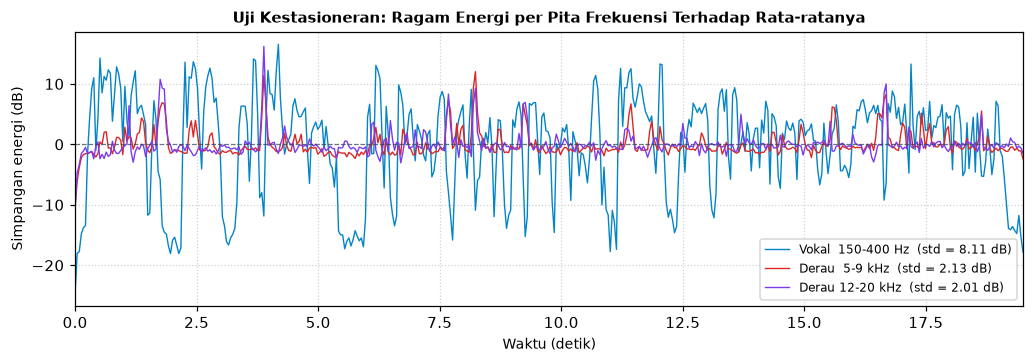

In [3]:
# STFT sebagai alat ukur energi pita per satuan waktu.
# n_fft 4096 pada 48 kHz = jendela 85 ms; hop 2048 = satu titik ukur tiap 42,7 ms.
N_FFT_UJI, HOP_UJI = 4096, 2048
S_uji = np.abs(librosa.stft(y, n_fft=N_FFT_UJI, hop_length=HOP_UJI))
f_uji = librosa.fft_frequencies(sr=sr, n_fft=N_FFT_UJI)
t_uji = librosa.frames_to_time(np.arange(S_uji.shape[1]), sr=sr, hop_length=HOP_UJI)


def energi_pita_db(S, f_bins, lo, hi):
    """Energi total (dB) pada pita [lo, hi) Hz untuk setiap bingkai waktu STFT."""
    sel = (f_bins >= lo) & (f_bins < hi)
    return 10 * np.log10(np.sum(S[sel] ** 2, axis=0) + 1e-20)


PITA = [
    ('Vokal  150-400 Hz',   150,   400, C_SIGNAL),
    ('Derau  5-9 kHz',     5000,  9000, C_ALERT),
    ('Derau 12-20 kHz',   12000, 20000, C_ACCENT),
]

print(f"Jumlah bingkai analisis : {S_uji.shape[1]} bingkai "
      f"(jendela {N_FFT_UJI/sr*1000:.0f} ms, langkah {HOP_UJI/sr*1000:.1f} ms)")
print(f"Resolusi frekuensi      : {sr/N_FFT_UJI:.2f} Hz per bin\n")
print(f"{'Pita':<20} {'min':>8} {'maks':>8} {'rentang':>9} {'std':>8}")
print("-" * 58)

profil = {}
for nama, lo, hi, _ in PITA:
    p = energi_pita_db(S_uji, f_uji, lo, hi)
    profil[nama] = p
    print(f"{nama:<20} {p.min():8.1f} {p.max():8.1f} {p.max()-p.min():8.1f}  {p.std():7.2f}")

std_vokal = profil['Vokal  150-400 Hz'].std()
std_derau = profil['Derau  5-9 kHz'].std()
print(f"\nRasio kestabilan: std pita vokal {std_vokal/std_derau:.1f}x lebih besar "
      f"daripada std pita derau.")

# Visualisasi: setiap profil digeser ke rata-ratanya sendiri (0 dB = rata-rata pita itu)
# supaya yang dibandingkan adalah RAGAM naik-turunnya, bukan tingkat absolutnya.
fig, ax = plt.subplots(figsize=(9.5, 3.4))
for nama, lo, hi, warna in PITA:
    p = profil[nama]
    ax.plot(t_uji, p - p.mean(), color=warna, lw=0.9,
            label=f"{nama}  (std = {p.std():.2f} dB)")

ax.axhline(0, color=C_NEUTRAL, lw=0.8, linestyle='--', alpha=0.7)
ax.set_title("Uji Kestasioneran: Ragam Energi per Pita Frekuensi Terhadap Rata-ratanya",
             fontsize=10, fontweight='bold')
ax.set_xlabel("Waktu (detik)", fontsize=9)
ax.set_ylabel("Simpangan energi (dB)", fontsize=9)
ax.set_xlim(0, t_uji[-1])
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower right', fontsize=8, ncol=1)
plt.tight_layout()
plt.show()

### Interpretasi uji kestasioneran

Angkanya memisahkan kedua kelompok dengan tegas. Pita vokal 150–400 Hz bergerak dalam rentang
**41,2 dB** dengan std **8,11 dB** — naik-turun tajam mengikuti suku kata yang dibaca. Dua pita
frekuensi tinggi justru jauh lebih rata: std hanya **2,13 dB** (5–9 kHz) dan **2,01 dB**
(12–20 kHz), yakni **sekitar 3,8 kali lebih stabil** daripada pita vokal. Pada grafik, kurva merah
dan violet terlihat seperti garis mendatar berbulu halus, sedangkan kurva biru melompat-lompat
dengan lembah dalam di setiap jeda kalimat.

Kesimpulannya, komponen dominan di atas 5 kHz **bukan** suara saya membaca, melainkan desis kipas
yang tingkat energinya konstan sepanjang 19,5 detik. Inilah definisi operasional derau statis:
statistiknya tidak bergantung pada waktu. Lompatan tajam yang sesekali muncul pada kurva merah dan
violet adalah bunyi desahan huruf *s*/*sy* (*sibilant*) dari pembacaan, yang memang menumpang di
pita frekuensi tinggi; namun kejadian itu hanya sesaat dan tidak mengubah tingkat dasar
(*noise floor*) di bawahnya — terbukti dari nilai minimum kedua pita yang tetap rapat.

Temuan ini akan terpakai lagi di §4: karena desis kipas stasioner dan menempati frekuensi tinggi,
ia menjadi "bahan bakar" utama aliasing ketika laju sampel diturunkan tanpa filter.

## §3. Representasi Audio 4 Dimensi

Satu berkas audio yang sama akan dibedah dari empat sudut pandang. Tidak ada satu tampilan pun
yang mampu menyajikan waktu, frekuensi, dan amplitudo secara tajam sekaligus — tiap tampilan
selalu mengorbankan salah satunya:

| Tampilan | Sumbu X | Sumbu Y | Yang terlihat | Yang hilang |
|---|---|---|---|---|
| Waveform | Waktu | Amplitudo | Dinamika volume, *clipping* | Seluruh informasi frekuensi |
| Spektrum FFT | Frekuensi | dBFS | Frekuensi dominan & dengung | Kapan bunyi itu terjadi |
| Spektrogram STFT | Waktu | Frekuensi (warna = energi) | Jejak harmonik & pita derau | Presisi (asas ketidakpastian) |
| Mel-Spektrogram | Waktu | Mel (warna = energi) | Pola perseptual / formant | Linearitas skala frekuensi |

### 3.1 Dimensi 1 — Waveform (Amplitudo vs Waktu)

Agar pembedaan bagian hening dan bagian vokal aktif tidak bersifat kira-kira, kedua daerah itu
saya **cari otomatis**: sinyal dipecah ke bingkai 0,25 detik, dihitung nilai RMS-nya, lalu bingkai
dengan RMS **terendah** ditandai sebagai *noise floor* (hanya derau kipas) dan bingkai dengan RMS
**tertinggi** sebagai puncak vokal aktif. Selisih keduanya adalah perkiraan SNR rekaman.

Bingkai analisis    : 78 bingkai x 0.25 detik
Daerah paling hening: bingkai #0 -> t = 0.00-0.25 s
  RMS               : -39.51 dBFS   (hanya derau kipas / noise floor)
  Puncak |x|        : 0.03769 -> -28.48 dBFS
Daerah paling aktif : bingkai #9 -> t = 2.25-2.50 s
  RMS               : -18.62 dBFS   (vokal pembacaan berita)
  Puncak |x|        : 0.34419 -> -9.26 dBFS

Perkiraan SNR       : 20.89 dB (selisih RMS vokal terhadap noise floor)
Median RMS bingkai  : -24.70 dBFS


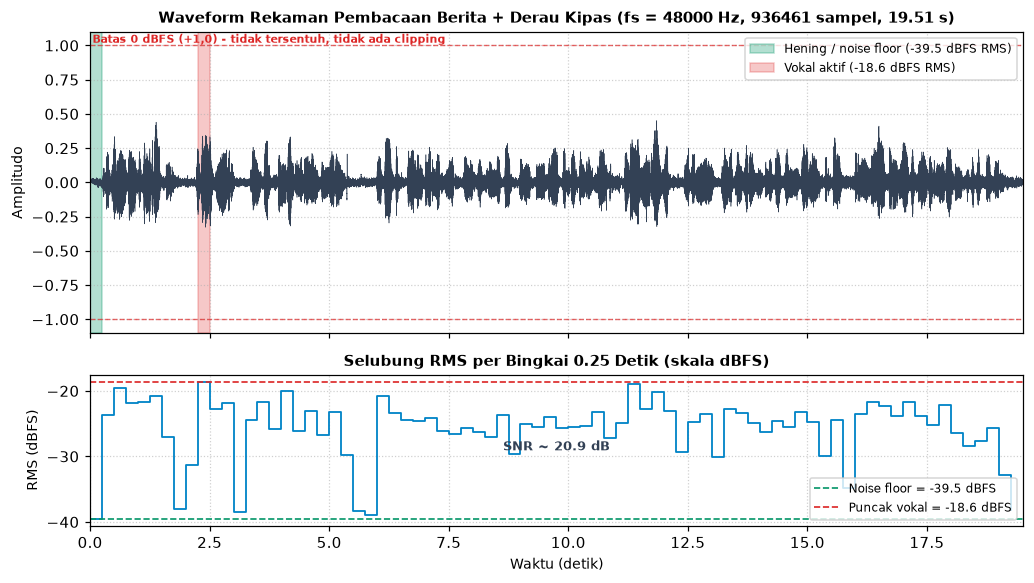


Audio asli (48 kHz, 4 detik pertama) - dengarkan deru kipas di belakang suara pembacaan:


In [4]:
# Pembagian sinyal ke bingkai 0,25 detik yang tidak tumpang tindih.
WIN_S = 0.25
win = int(WIN_S * sr)
n_win = len(y) // win
rms_win = np.array([np.sqrt(np.mean(y[i*win:(i+1)*win] ** 2)) for i in range(n_win)])
rms_db = 20 * np.log10(rms_win + 1e-12)

i_quiet = int(np.argmin(rms_db))     # bingkai paling hening -> derau kipas saja
i_loud = int(np.argmax(rms_db))      # bingkai paling nyaring -> vokal aktif

# Potongan sinyal untuk dua daerah tersebut; dipakai lagi pada analisis spektrum di 3.2.
y_noise = y[i_quiet*win:(i_quiet+1)*win]
y_voice = y[i_loud*win:(i_loud+1)*win]

rms_noise_db = 20 * np.log10(np.sqrt(np.mean(y_noise ** 2)))
rms_voice_db = 20 * np.log10(np.sqrt(np.mean(y_voice ** 2)))
snr_db = rms_voice_db - rms_noise_db

print(f"Bingkai analisis    : {n_win} bingkai x {WIN_S} detik")
print(f"Daerah paling hening: bingkai #{i_quiet} -> t = {i_quiet*WIN_S:.2f}-{(i_quiet+1)*WIN_S:.2f} s")
print(f"  RMS               : {rms_noise_db:.2f} dBFS   (hanya derau kipas / noise floor)")
print(f"  Puncak |x|        : {np.abs(y_noise).max():.5f} -> {20*np.log10(np.abs(y_noise).max()):.2f} dBFS")
print(f"Daerah paling aktif : bingkai #{i_loud} -> t = {i_loud*WIN_S:.2f}-{(i_loud+1)*WIN_S:.2f} s")
print(f"  RMS               : {rms_voice_db:.2f} dBFS   (vokal pembacaan berita)")
print(f"  Puncak |x|        : {np.abs(y_voice).max():.5f} -> {20*np.log10(np.abs(y_voice).max()):.2f} dBFS")
print(f"\nPerkiraan SNR       : {snr_db:.2f} dB (selisih RMS vokal terhadap noise floor)")
print(f"Median RMS bingkai  : {np.median(rms_db):.2f} dBFS")

fig, axes = plt.subplots(2, 1, figsize=(9.5, 5.4),
                         gridspec_kw={'height_ratios': [2, 1]}, sharex=True)

# --- Panel atas: waveform penuh, dengan kedua daerah temuan diberi sorotan ---
axes[0].plot(t, y, color=C_NEUTRAL, lw=0.35)
axes[0].axvspan(i_quiet*WIN_S, (i_quiet+1)*WIN_S, color=C_GOOD, alpha=0.30,
                label=f'Hening / noise floor ({rms_noise_db:.1f} dBFS RMS)')
axes[0].axvspan(i_loud*WIN_S, (i_loud+1)*WIN_S, color=C_ALERT, alpha=0.25,
                label=f'Vokal aktif ({rms_voice_db:.1f} dBFS RMS)')
# Garis batas 0 dBFS: jika waveform menyentuhnya berarti terjadi clipping.
for batas in (1.0, -1.0):
    axes[0].axhline(batas, color=C_ALERT, lw=0.9, linestyle='--', alpha=0.7)
axes[0].set_ylim(-1.1, 1.1)
axes[0].set_title(f"Waveform Rekaman Pembacaan Berita + Derau Kipas "
                  f"(fs = {sr} Hz, {len(y)} sampel, {len(y)/sr:.2f} s)",
                  fontsize=10, fontweight='bold')
axes[0].set_ylabel("Amplitudo", fontsize=9)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='upper right', fontsize=8)
axes[0].text(0.05, 1.02, "Batas 0 dBFS (+1,0) - tidak tersentuh, tidak ada clipping",
             color=C_ALERT, fontsize=7.5, fontweight='bold')

# --- Panel bawah: selubung RMS per bingkai, agar dinamikanya terbaca sebagai angka dB ---
axes[1].step(np.arange(n_win)*WIN_S, rms_db, where='post', color=C_SIGNAL, lw=1.2)
axes[1].axhline(rms_noise_db, color=C_GOOD, lw=1.1, linestyle='--',
                label=f'Noise floor = {rms_noise_db:.1f} dBFS')
axes[1].axhline(rms_voice_db, color=C_ALERT, lw=1.1, linestyle='--',
                label=f'Puncak vokal = {rms_voice_db:.1f} dBFS')
axes[1].annotate(f"SNR ~ {snr_db:.1f} dB",
                 xy=(t[-1]*0.5, (rms_noise_db+rms_voice_db)/2),
                 fontsize=8.5, fontweight='bold', color=C_NEUTRAL, ha='center')
axes[1].set_title(f"Selubung RMS per Bingkai {WIN_S} Detik (skala dBFS)",
                  fontsize=9.5, fontweight='bold')
axes[1].set_xlabel("Waktu (detik)", fontsize=9)
axes[1].set_ylabel("RMS (dBFS)", fontsize=9)
axes[1].set_xlim(0, t[-1])
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

putar(y, sr, f"\nAudio asli (48 kHz, {PREVIEW_S:.0f} detik pertama) - dengarkan deru kipas "
              f"di belakang suara pembacaan:")

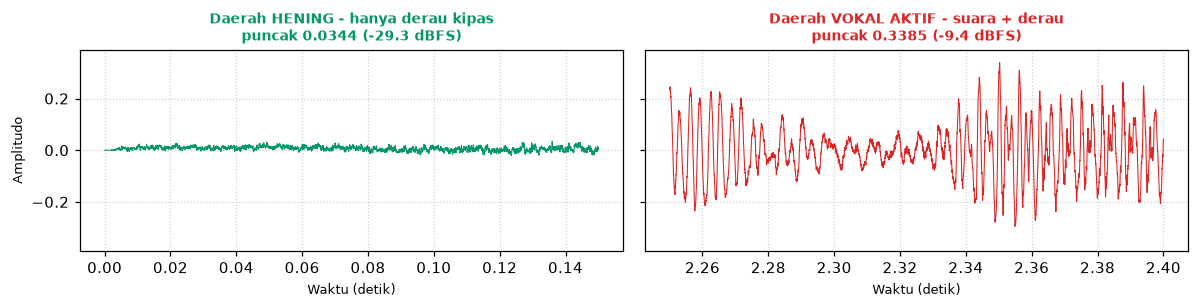

Perbandingan pada skala amplitudo yang sama (0.15 detik tiap panel):
  Puncak daerah hening : 0.03442
  Puncak daerah vokal  : 0.33846
  Rasio puncak         : 9.8x

Daerah hening TIDAK datar di nol - getarannya tetap ada, hanya jauh lebih kecil.


In [5]:
# Perbesaran 0,15 detik dari kedua daerah, digambar pada SKALA Y YANG SAMA.
# Tanpa skala yang disamakan, daerah hening akan tampak seolah-olah bergetar
# sekuat daerah vokal karena matplotlib meregangkan sumbunya secara otomatis.
ZOOM_S = 0.15
n_zoom = int(ZOOM_S * sr)
seg_noise = y_noise[:n_zoom]
seg_voice = y_voice[:n_zoom]
batas_y = np.abs(seg_voice).max() * 1.15

fig, axes = plt.subplots(1, 2, figsize=(11, 2.9), sharey=True)
for ax, seg, judul, warna, t0 in (
    (axes[0], seg_noise, 'Daerah HENING - hanya derau kipas', C_GOOD, i_quiet*WIN_S),
    (axes[1], seg_voice, 'Daerah VOKAL AKTIF - suara + derau', C_ALERT, i_loud*WIN_S),
):
    ax.plot(t0 + np.arange(len(seg))/sr, seg, color=warna, lw=0.7)
    ax.set_title(f"{judul}\npuncak {np.abs(seg).max():.4f} "
                 f"({20*np.log10(np.abs(seg).max()):.1f} dBFS)",
                 fontsize=9, fontweight='bold', color=warna)
    ax.set_xlabel("Waktu (detik)", fontsize=8.5)
    ax.grid(True, linestyle=':', alpha=0.6)
axes[0].set_ylabel("Amplitudo", fontsize=8.5)
axes[0].set_ylim(-batas_y, batas_y)
plt.tight_layout()
plt.show()

print(f"Perbandingan pada skala amplitudo yang sama ({ZOOM_S} detik tiap panel):")
print(f"  Puncak daerah hening : {np.abs(seg_noise).max():.5f}")
print(f"  Puncak daerah vokal  : {np.abs(seg_voice).max():.5f}")
print(f"  Rasio puncak         : {np.abs(seg_voice).max()/np.abs(seg_noise).max():.1f}x")
print("\nDaerah hening TIDAK datar di nol - getarannya tetap ada, hanya jauh lebih kecil.")

### Interpretasi waveform

Cara membedakan bagian hening dan bagian vokal aktif di waveform ini bertumpu pada **tinggi
selubung amplitudo**, bukan pada ada/tidaknya sinyal. Pencarian otomatis menempatkan jendela paling
hening di **detik 0,00–0,25**, yaitu saat perekam sudah menyala tetapi saya belum mulai membaca.
Perhatikan panel perbesaran: pada daerah itu garisnya **tidak pernah menjadi garis lurus nol**,
puncaknya masih 0,0344 — hanya 9,8 kali lebih kecil daripada puncak daerah vokal. Di situlah letak
perbedaan penting antara "hening" pada rekaman studio dan "hening" pada rekaman di depan kipas:
yang tersisa saat saya tidak bicara bukan keheningan, melainkan *noise floor* setebal
**−39,5 dBFS RMS** berupa deru kipas yang terus berjalan. Sebaliknya, daerah bersorot merah
(detik 2,25–2,50) menunjukkan selubung jauh lebih tinggi (**−18,6 dBFS RMS**) dengan pola
bergerombol khas suku kata: naik saat vokal dibunyikan dan turun sesaat pada konsonan letup.

Selisih kedua daerah memberi **SNR sekitar 20,9 dB**. Angka ini masuk kategori rekaman lapangan
yang wajar: suara masih jelas dominan, tetapi deraunya terukur dan tidak dapat diabaikan. Panel
selubung RMS memperjelas dinamika itu dalam satuan dB. Yang perlu diperhatikan di sana adalah
**lembah-lembahnya**: hampir semua jeda antar kalimat berhenti pada ketinggian yang berdekatan,
sekitar −31 sampai −39,5 dBFS, tidak pernah lebih rendah. Adanya lantai yang konsisten seperti itu
adalah tanda visual paling khas dari derau statis — kurva RMS boleh melonjak setinggi apa pun saat
bicara, tetapi ia tidak pernah bisa turun menembus lantai yang dipasang oleh kipas.

Namun justru di sinilah keterbatasan fatal waveform: dari gambar ini saya **tidak bisa tahu sama
sekali** pada frekuensi berapa deru kipas itu berada. Waveform "buta frekuensi" — dentuman 60 Hz
dan desis 8 kHz dengan amplitudo sama akan menghasilkan tinggi gambar yang identik. Untuk itulah
dimensi berikutnya diperlukan.

### 3.2 Dimensi 2 — Spektrum FFT dalam dBFS Terkalibrasi

Menulis spektrum sebagai `20*log10(abs(rfft(x)))` saja akan menghasilkan **bentuk kurva** yang
benar tetapi **angka sumbu Y yang salah**, karena tiga faktor skala belum dikoreksi:

1. **Panjang jendela** — hasil `rfft` tumbuh sebanding jumlah sampel, jadi harus dibagi.
2. **Rugi daya jendela Hann** — jendela Hann menipiskan tepi sinyal sehingga total bobotnya hanya
   sekitar setengah dari jendela kotak. Pembagian dilakukan terhadap `np.sum(w)`, bukan terhadap
   `n_fft`.
3. **Spektrum satu sisi** — `rfft` hanya menyimpan frekuensi positif, sehingga energi pasangan
   frekuensi negatif harus dikembalikan dengan mengalikan 2. Pengecualiannya bin DC dan bin
   Nyquist, yang memang tidak punya pasangan negatif — karena itu yang dikalikan hanya `mag[1:-1]`.

Setelah ketiga koreksi itu, sebuah sinus beramplitudo 1,0 akan terbaca tepat **0 dBFS**, amplitudo
0,5 terbaca **−6,02 dBFS**, dan seterusnya. Uji kalibrasi di bawah membuktikannya lebih dahulu,
supaya seluruh angka dBFS di notebook ini dapat dipercaya. Fungsi ini saya adopsi dari Modul 02
karena rumus kalibrasinya sudah benar dan ingin saya pakai konsisten.

In [6]:
def spectrum_dbfs(x, sr, n_fft=4096, average=True):
    """Menghitung spektrum satu sisi berskala dBFS yang terkalibrasi.

    Bila average=True dan sinyal lebih panjang dari satu jendela, magnitudo
    dirata-ratakan lintas jendela yang saling bertumpang tindih 50%.
    Mengembalikan (frekuensi_hz, magnitudo_dbfs).
    """
    x = np.asarray(x, dtype=float)
    if len(x) < n_fft:                      # sinyal pendek dipadatkan nol agar rfft tetap jalan
        x = np.pad(x, (0, n_fft - len(x)))

    w = get_window('hann', n_fft, fftbins=True)   # jendela periodik, bukan np.hanning
    hop = n_fft // 2
    n_frames = 1 + (len(x) - n_fft) // hop if average else 1

    akumulasi = np.zeros(n_fft // 2 + 1)
    for i in range(n_frames):
        seg = x[i * hop: i * hop + n_fft]
        akumulasi += np.abs(np.fft.rfft(seg * w))
    mag = akumulasi / n_frames / np.sum(w)        # koreksi 1 & 2 sekaligus

    mag[1:-1] *= 2.0                             # koreksi 3: spektrum satu sisi

    db = 20 * np.log10(np.maximum(mag, 1e-12))   # lantai 1e-12 mencegah log(0)
    freqs = np.fft.rfftfreq(n_fft, 1 / sr)
    return freqs, db


# --- Uji kalibrasi: nada uji diletakkan tepat di tengah bin agar bebas scalloping loss ---
N_UJI = 4096
f_bin_uji = np.fft.rfftfreq(N_UJI, 1 / sr)
f_nada = f_bin_uji[85]                            # bin ke-85 ~ 996 Hz, tepat di tengah bin
t_nada = np.arange(N_UJI) / sr

print("Verifikasi kalibrasi dBFS (nada uji tepat di tengah bin):")
print(f"  Frekuensi nada uji : {f_nada:.2f} Hz\n")
print(f"  {'amplitudo':>10} {'terbaca (dBFS)':>16} {'target (dBFS)':>15} {'galat':>10}")
for amp in (1.0, 0.5, 0.1, 0.01):
    _, db_uji = spectrum_dbfs(amp * np.sin(2*np.pi*f_nada*t_nada), sr, n_fft=N_UJI)
    target = 20 * np.log10(amp)
    print(f"  {amp:>10} {db_uji.max():>16.4f} {target:>15.2f} {db_uji.max()-target:>+10.4f}")

print("\nGalatnya nol pada empat tingkat amplitudo. Sumbu dBFS di seluruh grafik berikut sahih.")
print("Catatan: nada yang tidak tepat di tengah bin akan terbaca ~0,3 dB lebih rendah")
print("(gejala scalloping loss) - sifat wajar analisis FFT, bukan kesalahan program.")

Verifikasi kalibrasi dBFS (nada uji tepat di tengah bin):
  Frekuensi nada uji : 996.09 Hz

   amplitudo   terbaca (dBFS)   target (dBFS)      galat
         1.0           0.0000            0.00    +0.0000
         0.5          -6.0206           -6.02    +0.0000
         0.1         -20.0000          -20.00    +0.0000
        0.01         -40.0000          -40.00    +0.0000

Galatnya nol pada empat tingkat amplitudo. Sumbu dBFS di seluruh grafik berikut sahih.
Catatan: nada yang tidak tepat di tengah bin akan terbaca ~0,3 dB lebih rendah
(gejala scalloping loss) - sifat wajar analisis FFT, bukan kesalahan program.


Resolusi spektrum rekaman penuh : 5.86 Hz per bin
Resolusi spektrum potongan      : 11.72 Hz per bin

Puncak paling menonjol pada spektrum derau murni (20-4000 Hz):
     frekuensi      tingkat   prominensi
      187.5 Hz     -51.3 dBFS      16.9 dB
      363.3 Hz     -52.3 dBFS      12.8 dB
      480.5 Hz     -54.2 dBFS      13.5 dB
     2835.9 Hz     -63.9 dBFS      12.5 dB
     3152.3 Hz     -63.3 dBFS      13.2 dB
     3750.0 Hz     -66.4 dBFS      10.6 dB

Frekuensi tonal paling dominan : 187.5 Hz
Uji keluarga harmonik terhadap 187.5 Hz:
      187.5 Hz = 1.00 x 187.5 Hz  -> harmonik ke-1
      363.3 Hz = 1.94 x 187.5 Hz  -> harmonik ke-2
      480.5 Hz = 2.56 x 187.5 Hz  -> bukan harmonik
     2835.9 Hz = 15.12 x 187.5 Hz  -> bukan harmonik
     3152.3 Hz = 16.81 x 187.5 Hz  -> bukan harmonik
     3750.0 Hz = 20.00 x 187.5 Hz  -> harmonik ke-20

Sebaran energi derau murni per pita (dihitung dari potongan hening):
              pita     energi     per Hz
      20-   100 Hz   -45.3 d

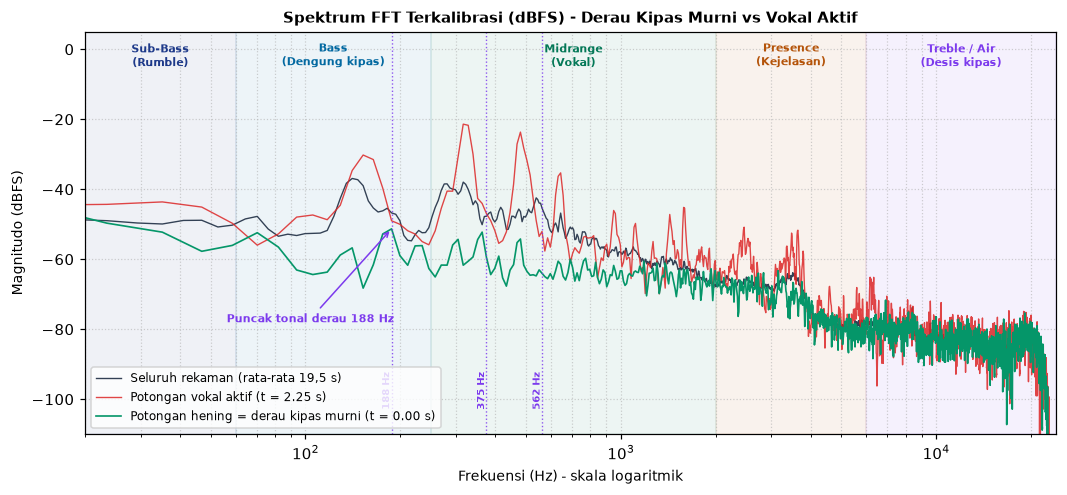

In [7]:
# Tiga spektrum dibandingkan dalam satu bidang:
#  - seluruh rekaman (rata-rata 19,5 detik)
#  - potongan hening 0,25 s  -> inilah spektrum MURNI derau kipas
#  - potongan vokal 0,25 s   -> spektrum suara + derau
N_FFT_SPEC = 8192            # df = 5,86 Hz: cukup halus untuk memisahkan harmonik kipas
N_FFT_SEG = 4096             # potongan 0,25 s hanya 12.000 sampel, jendela dibuat lebih pendek

freqs, db_full = spectrum_dbfs(y, sr, n_fft=N_FFT_SPEC)
freqs_seg, db_noise = spectrum_dbfs(y_noise, sr, n_fft=N_FFT_SEG)
_, db_voice = spectrum_dbfs(y_voice, sr, n_fft=N_FFT_SEG)

print(f"Resolusi spektrum rekaman penuh : {sr/N_FFT_SPEC:.2f} Hz per bin")
print(f"Resolusi spektrum potongan      : {sr/N_FFT_SEG:.2f} Hz per bin\n")

# --- Mencari frekuensi dominan derau: puncak dicari pada spektrum potongan HENING,
# karena di situ tidak ada vokal yang mengaburkan jejak kipas. ---
cari = (freqs_seg >= 20) & (freqs_seg <= 4000)
idx_cari = np.where(cari)[0]
jarak_bin = max(1, int(50 / (sr / N_FFT_SEG)))    # puncak minimal berjarak 50 Hz
puncak, props = find_peaks(db_noise[idx_cari], prominence=4.0, distance=jarak_bin)
f_puncak = freqs_seg[idx_cari[puncak]]
db_puncak = db_noise[idx_cari[puncak]]
prom = props['prominences']

urut = np.argsort(prom)[::-1][:6]                 # enam puncak paling menonjol
print("Puncak paling menonjol pada spektrum derau murni (20-4000 Hz):")
print(f"  {'frekuensi':>12} {'tingkat':>12} {'prominensi':>12}")
for k in sorted(urut, key=lambda q: f_puncak[q]):
    print(f"  {f_puncak[k]:>9.1f} Hz {db_puncak[k]:>9.1f} dBFS {prom[k]:>9.1f} dB")

f_dom = f_puncak[int(np.argmax(prom))]
print(f"\nFrekuensi tonal paling dominan : {f_dom:.1f} Hz")
print(f"Uji keluarga harmonik terhadap {f_dom:.1f} Hz:")
for k in sorted(urut, key=lambda q: f_puncak[q]):
    rasio = f_puncak[k] / f_dom
    cocok = abs(rasio - round(rasio)) < 0.10 and round(rasio) >= 1
    print(f"  {f_puncak[k]:>9.1f} Hz = {rasio:4.2f} x {f_dom:.1f} Hz  "
          f"{'-> harmonik ke-' + str(round(rasio)) if cocok else '-> bukan harmonik'}")

# --- Energi derau murni per pita oktaf, untuk melihat bentuk sebaran spektrumnya ---
print("\nSebaran energi derau murni per pita (dihitung dari potongan hening):")
print(f"  {'pita':>16} {'energi':>10} {'per Hz':>10}")
for lo, hi in [(20, 100), (100, 300), (300, 1000), (1000, 4000),
               (4000, 8000), (8000, 16000), (16000, 24000)]:
    sel = (freqs_seg >= lo) & (freqs_seg < hi)
    daya = 10 * np.log10(np.sum(10 ** (db_noise[sel] / 10)))
    print(f"  {lo:6d}-{hi:6d} Hz {daya:7.1f} dB {daya-10*np.log10(hi-lo):7.1f} dB/Hz")

# --- Grafik ---
ZONA = [
    (20,   60,    'Sub-Bass\n(Rumble)',           '#1e3a8a'),
    (60,   250,   'Bass\n(Dengung kipas)',        '#0369a1'),
    (250,  2000,  'Midrange\n(Vokal)',            '#047857'),
    (2000, 6000,  'Presence\n(Kejelasan)',        '#b45309'),
    (6000, 24000, 'Treble / Air\n(Desis kipas)',  '#7c3aed'),
]

fig, ax = plt.subplots(figsize=(9.8, 4.6))
for f_lo, f_hi, label, warna in ZONA:
    ax.axvspan(f_lo, f_hi, color=warna, alpha=0.07)
    ax.text(np.sqrt(f_lo*f_hi), 2, label, ha='center', va='top',
            fontsize=7, fontweight='bold', color=warna)

ax.semilogx(freqs[1:], db_full[1:], color=C_NEUTRAL, lw=0.9,
            label='Seluruh rekaman (rata-rata 19,5 s)')
ax.semilogx(freqs_seg[1:], db_voice[1:], color=C_ALERT, lw=0.9, alpha=0.85,
            label=f'Potongan vokal aktif (t = {i_loud*WIN_S:.2f} s)')
ax.semilogx(freqs_seg[1:], db_noise[1:], color=C_GOOD, lw=1.1,
            label=f'Potongan hening = derau kipas murni (t = {i_quiet*WIN_S:.2f} s)')

# Menandai frekuensi tonal dominan beserta dua harmonik pertamanya.
for k in (1, 2, 3):
    if f_dom * k < sr / 2:
        ax.axvline(f_dom*k, color=C_ACCENT, lw=0.9, linestyle=':', alpha=0.85)
        ax.text(f_dom*k, -103, f"{f_dom*k:.0f} Hz", rotation=90, fontsize=6.8,
                fontweight='bold', color=C_ACCENT, ha='right', va='bottom')

ax.annotate(f"Puncak tonal derau {f_dom:.0f} Hz",
            xy=(f_dom, db_noise[int(np.argmin(np.abs(freqs_seg-f_dom)))]),
            xytext=(f_dom*0.30, -78), fontsize=7.5, fontweight='bold', color=C_ACCENT,
            ha='left', arrowprops=dict(arrowstyle='->', color=C_ACCENT, lw=1.0))

ax.set_title("Spektrum FFT Terkalibrasi (dBFS) - Derau Kipas Murni vs Vokal Aktif",
             fontsize=10, fontweight='bold')
ax.set_xlabel("Frekuensi (Hz) - skala logaritmik", fontsize=9)
ax.set_ylabel("Magnitudo (dBFS)", fontsize=9)
ax.set_xlim(20, sr/2)
ax.set_ylim(-110, 5)
ax.grid(True, which='both', linestyle=':', alpha=0.6)
ax.legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()

### Interpretasi spektrum FFT

Kurva hijau adalah jawaban atas pertanyaan "frekuensi berapa yang mendominasi derau statis saya".
Derau kipas ini ternyata punya **dua wajah sekaligus**:

**Pertama, puncak tonal di frekuensi rendah.** Puncak paling menonjol berada di **187,5 Hz**
(−51,3 dBFS, prominensi 16,9 dB), diikuti puncak kedua di **363,3 Hz** yang besarnya 1,94× puncak
pertama. Rasio yang praktis 1 : 2 itu adalah tanda sumber **berputar periodik**: frekuensi dasar
lahir dari jumlah bilah kipas dikali putaran per detik, dan kelipatannya muncul sebagai harmonik
yang melemah. Satu kejujuran pengukuran perlu disebut: resolusi analisis di sini **±11,7 Hz**,
sehingga "187,5 Hz" sebenarnya berarti "di suatu tempat antara 182 dan 193 Hz". Kalau nada dasar
sesungguhnya ≈181,7 Hz, maka 363,3 Hz jatuh tepat pada 2×-nya — dan selisih terhadap 187,5 Hz
masih berada di dalam satu bin. Jadi yang dapat saya klaim dengan aman adalah: **ada keluarga
harmonik dengan nada dasar di kisaran 182–188 Hz**, bukan satu angka presisi tinggi.

Perlu diingat juga satu jebakan penalaran: puncak tertinggi pada grafik bukan otomatis nada dasar,
karena tinggi puncak bergantung pada seberapa sepi frekuensi di sekitarnya. Karena itu saya
menguji hubungan **kelipatan bulat** antar puncak, bukan sekadar mengambil yang tertinggi. Uji itu
juga menyaring dengan jujur: puncak di 480,5 Hz (2,56×), 2.836 Hz, dan 3.152 Hz **bukan** anggota
keluarga harmonik tersebut, jadi tidak saya klaim sebagai jejak kipas.

**Kedua, dataran desis broadband di frekuensi tinggi.** Di atas 4 kHz kurva hijau melandai menjadi
dataran panjang yang hampir rata sampai ±22 kHz, dengan kerapatan energi sekitar **−90 dB/Hz**
pada 4–8 kHz dan turun perlahan ke −95 dB/Hz di atas 16 kHz. Komponen inilah turbulensi udara
kipas. Meski tingkatnya jauh di bawah puncak tonal, cakupannya sangat lebar — dan justru
**dataran inilah yang nanti melipat balik menjadi aliasing** di §4.

Perbandingan dengan kurva merah (vokal aktif) menegaskan pembagian wilayah. Di rentang 250–700 Hz
kurva merah menjulang sekitar **25–30 dB** di atas kurva hijau: itu energi harmonik suara saya.
Namun mulai sekitar 2 kHz keduanya merapat, dan di atas 5 kHz **berhimpitan hampir sempurna** —
pada frekuensi tinggi, yang terekam memang praktis hanya kipas, baik ketika saya bicara maupun
ketika saya diam. Ini konsisten dengan uji kestasioneran di §2.3, dan sekaligus menjelaskan
mengapa spektrum rata-rata seluruh rekaman (kurva abu-abu) berada di antara keduanya: ia adalah
rerata bagian bersuara dan bagian hening.

Sisi lemah tampilan ini: spektrum FFT adalah **satu potret rata-rata** — sumbu waktu hilang
sepenuhnya. Dari grafik ini saya tidak bisa membuktikan bahwa desis itu memang menyala terus dan
tidak muncul-hilang. Pembuktian itu tugas spektrogram.

### 3.3 Dimensi 3 — Spektrogram STFT (Waktu × Frekuensi)

STFT menggeser jendela analisis di sepanjang sinyal sehingga waktu dan frekuensi tampil sekaligus,
dengan warna sebagai dimensi energi. Pilihan `n_fft = 2048` pada 48 kHz memberi resolusi
frekuensi $\Delta f = f_s / n_{fft} = 23{,}4$ Hz dengan panjang jendela 42,7 ms — cukup halus untuk
memisahkan harmonik kipas yang berjarak ±140 Hz, sekaligus cukup pendek agar suku kata tidak
melebur. Inilah pertukaran mendasar analisis waktu-frekuensi: memperpanjang jendela menajamkan
frekuensi tetapi mengaburkan waktu, dan sebaliknya.

Dua panel ditampilkan karena keduanya menjawab pertanyaan berbeda: panel atas (0–4 kHz) untuk
melihat struktur harmonik vokal, panel bawah (0–24 kHz penuh) untuk memperlihatkan pita desis
kipas yang tidak pernah padam.

Dimensi STFT     : 1025 bin frekuensi x 1830 bingkai waktu
Resolusi frekuensi: 23.44 Hz per bin
Panjang jendela  : 42.7 ms | langkah: 10.7 ms


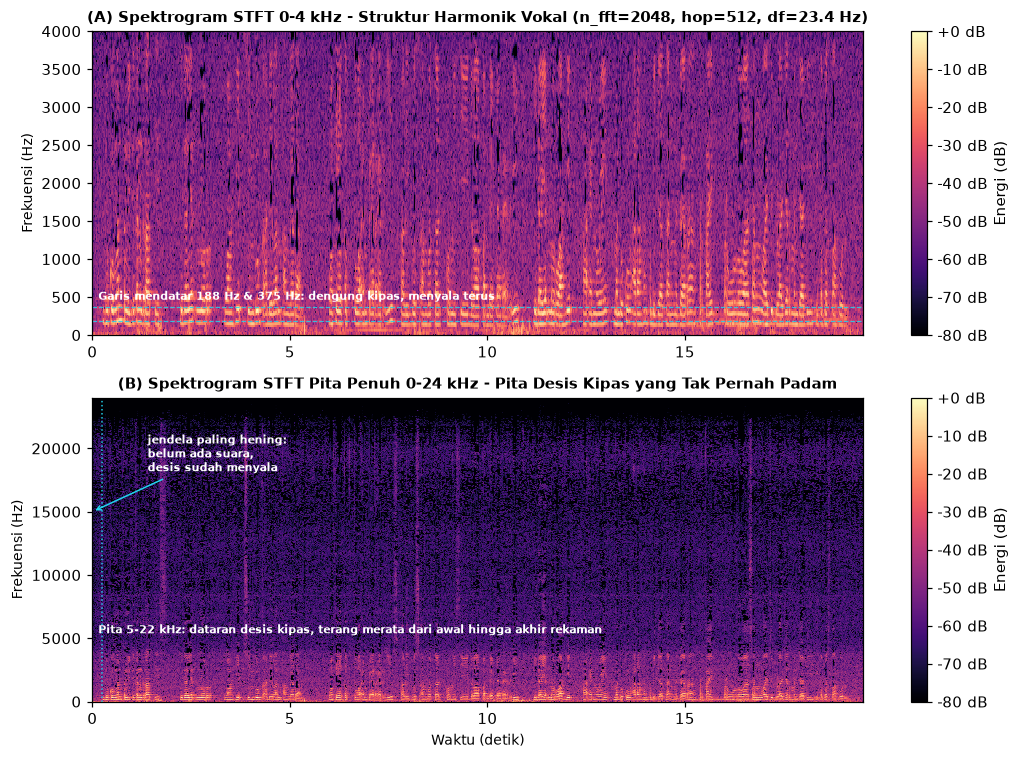


Rata-rata energi spektrogram: saat HENING vs saat BICARA (dB relatif puncak)
              pita    hening    bicara   selisih
     100-   400 Hz   -44.3 dB   -25.0 dB   +19.3 dB
     400-  1000 Hz   -49.3 dB   -37.5 dB   +11.8 dB
    1000-  4000 Hz   -54.3 dB   -50.8 dB    +3.5 dB
    5000-  9000 Hz   -66.2 dB   -65.6 dB    +0.6 dB
   12000- 20000 Hz   -70.1 dB   -70.2 dB    -0.2 dB


In [8]:
N_FFT, HOP = 2048, 512
S_mag = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP))
S_db = librosa.amplitude_to_db(S_mag, ref=np.max)   # magnitudo -> dB relatif puncak

print(f"Dimensi STFT     : {S_db.shape[0]} bin frekuensi x {S_db.shape[1]} bingkai waktu")
print(f"Resolusi frekuensi: {sr/N_FFT:.2f} Hz per bin")
print(f"Panjang jendela  : {N_FFT/sr*1000:.1f} ms | langkah: {HOP/sr*1000:.1f} ms")

fig, axes = plt.subplots(2, 1, figsize=(9.8, 7.0))

# --- Panel A: zoom 0-4 kHz, wilayah harmonik vokal ---
img0 = librosa.display.specshow(S_db, sr=sr, hop_length=HOP, n_fft=N_FFT,
                                x_axis='time', y_axis='linear', ax=axes[0], cmap='magma')
axes[0].set_ylim(0, 4000)
axes[0].set_title(f"(A) Spektrogram STFT 0-4 kHz - Struktur Harmonik Vokal "
                  f"(n_fft={N_FFT}, hop={HOP}, df={sr/N_FFT:.1f} Hz)",
                  fontsize=9.5, fontweight='bold')
axes[0].set_ylabel("Frekuensi (Hz)", fontsize=9)
axes[0].set_xlabel("")
fig.colorbar(img0, ax=axes[0], format='%+2.0f dB', label='Energi (dB)')

# Garis dengung kipas 140,6 Hz beserta harmonik ke-2, ditandai di panel zoom.
for k in (1, 2):
    axes[0].axhline(f_dom*k, color='#22d3ee', lw=0.8, linestyle='--', alpha=0.85)
axes[0].text(0.15, f_dom*2 + 90, f"Garis mendatar {f_dom:.0f} Hz & {2*f_dom:.0f} Hz: "
                                 f"dengung kipas, menyala terus",
             color='white', fontsize=7.5, fontweight='bold')

# --- Panel B: seluruh pita sampai Nyquist 24 kHz ---
img1 = librosa.display.specshow(S_db, sr=sr, hop_length=HOP, n_fft=N_FFT,
                                x_axis='time', y_axis='linear', ax=axes[1], cmap='magma')
axes[1].set_ylim(0, sr/2)
axes[1].set_title(f"(B) Spektrogram STFT Pita Penuh 0-{sr/2000:.0f} kHz - "
                  f"Pita Desis Kipas yang Tak Pernah Padam",
                  fontsize=9.5, fontweight='bold')
axes[1].set_ylabel("Frekuensi (Hz)", fontsize=9)
axes[1].set_xlabel("Waktu (detik)", fontsize=9)
fig.colorbar(img1, ax=axes[1], format='%+2.0f dB', label='Energi (dB)')

# Menandai jendela hening: di sini vokal berhenti, namun pita desis di atasnya tetap terang.
axes[1].axvspan(i_quiet*WIN_S, (i_quiet+1)*WIN_S, color='#22d3ee', alpha=0.0)
for x_garis in (i_quiet*WIN_S, (i_quiet+1)*WIN_S):
    axes[1].axvline(x_garis, color='#22d3ee', lw=1.0, linestyle=':', alpha=0.95)
axes[1].annotate("jendela paling hening:\nbelum ada suara,\ndesis sudah menyala",
                 xy=(i_quiet*WIN_S, 15000),
                 xytext=(i_quiet*WIN_S + 1.4, 18200),
                 color='white', fontsize=7.2, fontweight='bold',
                 arrowprops=dict(arrowstyle='->', color='#22d3ee', lw=1.0))
axes[1].axhspan(5000, 22000, color='white', alpha=0.0)
axes[1].text(0.15, 5400, "Pita 5-22 kHz: dataran desis kipas, terang merata dari awal "
                         "hingga akhir rekaman",
             color='white', fontsize=7.5, fontweight='bold')

plt.tight_layout()
plt.show()

# Bukti angka: rata-rata energi tiap baris frekuensi pada saat JEDA vs saat BICARA.
bingkai_quiet = librosa.time_to_frames([i_quiet*WIN_S, (i_quiet+1)*WIN_S], sr=sr, hop_length=HOP)
bingkai_loud = librosa.time_to_frames([i_loud*WIN_S, (i_loud+1)*WIN_S], sr=sr, hop_length=HOP)
f_stft = librosa.fft_frequencies(sr=sr, n_fft=N_FFT)

print("\nRata-rata energi spektrogram: saat HENING vs saat BICARA (dB relatif puncak)")
print(f"  {'pita':>16} {'hening':>9} {'bicara':>9} {'selisih':>9}")
for lo, hi in [(100, 400), (400, 1000), (1000, 4000), (5000, 9000), (12000, 20000)]:
    sel = (f_stft >= lo) & (f_stft < hi)
    e_q = S_db[sel, bingkai_quiet[0]:bingkai_quiet[1]].mean()
    e_l = S_db[sel, bingkai_loud[0]:bingkai_loud[1]].mean()
    print(f"  {lo:6d}-{hi:6d} Hz {e_q:7.1f} dB {e_l:7.1f} dB {e_l-e_q:+7.1f} dB")

### Interpretasi spektrogram STFT

Inilah tampilan yang paling telanjang memperlihatkan sifat derau statis. Pada panel (B), pita
**5–22 kHz** tampak sebagai **dataran berwarna seragam yang membentang utuh dari detik 0 sampai
detik 19,5** — tanpa satu pun celah gelap. Tepat itulah tanda tangan visual derau statis: karena
statistiknya tidak bergantung waktu, warnanya pun tidak berubah terhadap waktu. Saya menandai
jendela paling hening dengan dua garis titik-titik: di dalam koridor itu struktur harmonik vokal
di bagian bawah gambar belum muncul, tetapi dataran desis di atasnya **sudah menyala penuh**.

Angka pembandingnya menguatkan hal itu secara kuantitatif, dan hasilnya bahkan lebih tegas
daripada yang terlihat mata. Saat berpindah dari hening ke bicara, pita 100–400 Hz melonjak
**+19,3 dB** dan pita 400–1000 Hz **+11,8 dB**. Sebaliknya pita 5–9 kHz hanya bergerak
**+0,6 dB**, dan pita 12–20 kHz justru **−0,2 dB** — praktis nol, bahkan sedikit lebih rendah saat
saya bicara. Jadi pada frekuensi tinggi, spektrogram sepenuhnya menampilkan kipas; pada frekuensi
rendah, ia menampilkan campuran kipas dan suara. Perlu dicatat bahwa angka-angka ini adalah
rata-rata; lonjakan sesaat akibat huruf desis tetap ada, hanya saja terlalu singkat untuk
menggeser rata-rata satu jendela 0,25 detik.

Pada panel (A) yang diperbesar ke 0–4 kHz, dua pola visual dapat dibedakan dengan jelas:
**garis-garis mendatar lurus** pada 188 Hz dan 375 Hz (dengung tonal kipas yang tak pernah padam),
versus **berkas garis harmonik bergelombang** yang naik-turun mengikuti intonasi saya membaca,
diselingi **paku vertikal** pada setiap konsonan letup. Perbedaan bentuk inilah alasan tugas ini
mensyaratkan derau statis: garis lurus mendatar mudah dipisahkan secara visual dari harmonik vokal
yang dinamis. Kalau sumber deraunya klakson atau ketukan pintu, yang muncul justru paku vertikal
yang menyerupai transien konsonan, sehingga derau dan suara menjadi sulit dibedakan.

### 3.4 Dimensi 4 — Mel-Spektrogram (Skala Perseptual)

Telinga manusia tidak mendengar frekuensi secara linier. Selisih 100 Hz antara 100 Hz dan 200 Hz
terdengar sejauh satu oktaf, sedangkan selisih yang sama antara 10.000 Hz dan 10.100 Hz praktis
tidak terdengar. **Skala Mel** memodelkan ketimpangan itu:

$$m = 2595 \log_{10}\left(1 + \frac{f}{700}\right)$$

Akibatnya, separuh pertama sumbu Mel hanya dipakai untuk beberapa ribu Hz pertama — justru wilayah
tempat **formant** suara manusia berada. Formant adalah puncak-puncak resonansi rongga mulut dan
tenggorokan yang menentukan bunyi vokal /a/, /i/, /u/; posisi F1 dan F2 itulah yang membuat kita
mengenali huruf vokal, dan keduanya hampir selalu berada di bawah 3 kHz.

Satu catatan teknis yang mudah terlewat: rumus di atas adalah varian **HTK**, sedangkan
`librosa` secara bawaan memakai varian **Slaney**. Keduanya sahih namun angkanya berbeda. Di sini
saya memakai bawaan librosa supaya perhitungan `melspectrogram` dan sumbu gambar `specshow`
konsisten satu sama lain.

Filterbank Mel: 128 filter, rentang 0 - 24000 Hz
  filter dengan pusat <= 1 kHz :  32 dari 128 (25% tinggi sumbu, padahal hanya 4.2% lebar pita fisik)
  filter dengan pusat <= 4 kHz :  73 dari 128 (57% tinggi sumbu, padahal hanya 16.7% lebar pita fisik)

Lebar filter melebar seiring naiknya frekuensi:
  filter ke-1    berpusat      32.1 Hz  (lebar ~     64.3 Hz)
  filter ke-10   berpusat     321.4 Hz  (lebar ~     64.3 Hz)
  filter ke-30   berpusat     964.2 Hz  (lebar ~     64.3 Hz)
  filter ke-60   berpusat    2604.9 Hz  (lebar ~    172.7 Hz)
  filter ke-90   berpusat    7040.7 Hz  (lebar ~    466.8 Hz)
  filter ke-120  berpusat   19030.5 Hz  (lebar ~   1261.7 Hz)


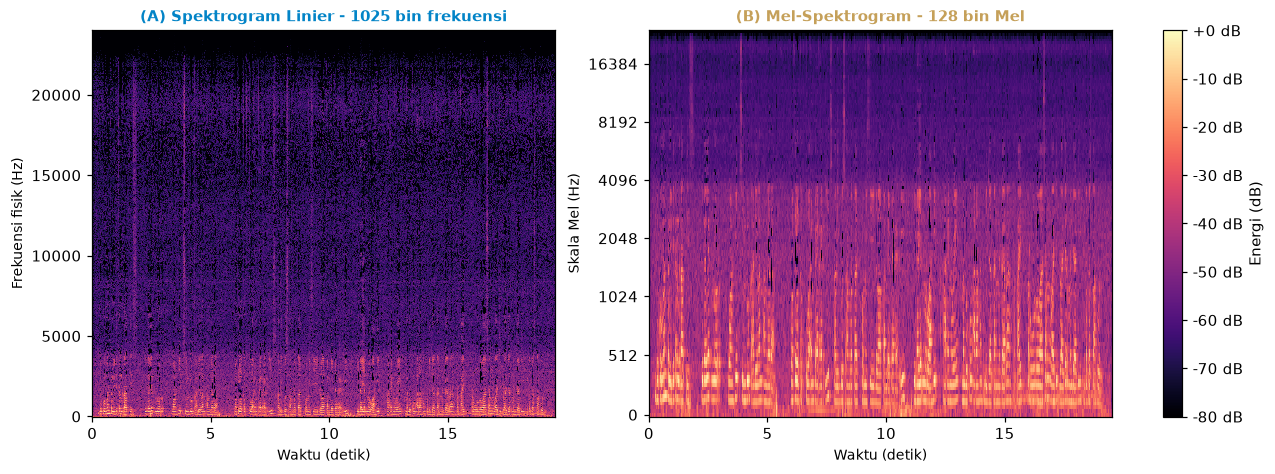


Dimensi spektrogram linier :  1025 bin x 1830 bingkai
Dimensi Mel-spektrogram    :   128 bin x 1830 bingkai
Pemampatan data            : 8.0x lebih ringkas


In [9]:
N_MELS = 128

# Sebaran filter Mel: membuktikan bahwa pita rendah mendapat porsi sumbu jauh lebih besar.
mel_f = librosa.mel_frequencies(n_mels=N_MELS, fmin=0, fmax=sr/2)
n_bawah_1k = int(np.sum(mel_f <= 1000))
n_bawah_4k = int(np.sum(mel_f <= 4000))
print(f"Filterbank Mel: {N_MELS} filter, rentang 0 - {sr/2:.0f} Hz")
print(f"  filter dengan pusat <= 1 kHz : {n_bawah_1k:3d} dari {N_MELS} "
      f"({100*n_bawah_1k/N_MELS:.0f}% tinggi sumbu, padahal hanya "
      f"{100*1000/(sr/2):.1f}% lebar pita fisik)")
print(f"  filter dengan pusat <= 4 kHz : {n_bawah_4k:3d} dari {N_MELS} "
      f"({100*n_bawah_4k/N_MELS:.0f}% tinggi sumbu, padahal hanya "
      f"{100*4000/(sr/2):.1f}% lebar pita fisik)")
print("\nLebar filter melebar seiring naiknya frekuensi:")
for i in (1, 10, 30, 60, 90, 120):
    print(f"  filter ke-{i:<4} berpusat {mel_f[i]:9.1f} Hz  (lebar ~ {mel_f[i+1]-mel_f[i-1]:8.1f} Hz)")

# Spektrogram Mel: melspectrogram mengembalikan DAYA (power=2.0 bawaan), sehingga
# konversi ke dB WAJIB memakai power_to_db - bukan amplitude_to_db seperti pada magnitudo STFT.
S_mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
S_mel_db = librosa.power_to_db(S_mel, ref=np.max)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), constrained_layout=True)

librosa.display.specshow(S_db, sr=sr, hop_length=HOP, n_fft=N_FFT,
                         x_axis='time', y_axis='linear', ax=axes[0], cmap='magma')
axes[0].set_title("(A) Spektrogram Linier - 1025 bin frekuensi",
                  fontsize=9.5, fontweight='bold', color=C_SIGNAL)
axes[0].set_ylabel("Frekuensi fisik (Hz)", fontsize=9)

img = librosa.display.specshow(S_mel_db, sr=sr, hop_length=HOP, n_fft=N_FFT,
                               x_axis='time', y_axis='mel', ax=axes[1], cmap='magma')
axes[1].set_title(f"(B) Mel-Spektrogram - {N_MELS} bin Mel",
                  fontsize=9.5, fontweight='bold', color=C_GOLD)
axes[1].set_ylabel("Skala Mel (Hz)", fontsize=9)
for ax in axes:
    ax.set_xlabel("Waktu (detik)", fontsize=9)
fig.colorbar(img, ax=axes, format='%+2.0f dB', label='Energi (dB)')
plt.show()

print(f"\nDimensi spektrogram linier : {S_db.shape[0]:>5} bin x {S_db.shape[1]} bingkai")
print(f"Dimensi Mel-spektrogram    : {S_mel_db.shape[0]:>5} bin x {S_mel_db.shape[1]} bingkai")
print(f"Pemampatan data            : {S_db.shape[0]/S_mel_db.shape[0]:.1f}x lebih ringkas")

Perkiraan formant pada potongan vokal aktif (dari selubung spektrum yang dihaluskan):
  F1 ~   328.1 Hz  ->  jatuh di bin Mel ke- 10/128 (   8% tinggi sumbu Mel,  1.4% tinggi sumbu linier)
  F2 ~  1464.8 Hz  ->  jatuh di bin Mel ke- 43/128 (  34% tinggi sumbu Mel,  6.1% tinggi sumbu linier)
  F3 ~  2496.1 Hz  ->  jatuh di bin Mel ke- 59/128 (  46% tinggi sumbu Mel, 10.4% tinggi sumbu linier)

Seluruh wilayah formant (<= 3,5 kHz) memakai 69/128 bin Mel (54% tinggi gambar), sedangkan pada sumbu linier hanya 14.6%.


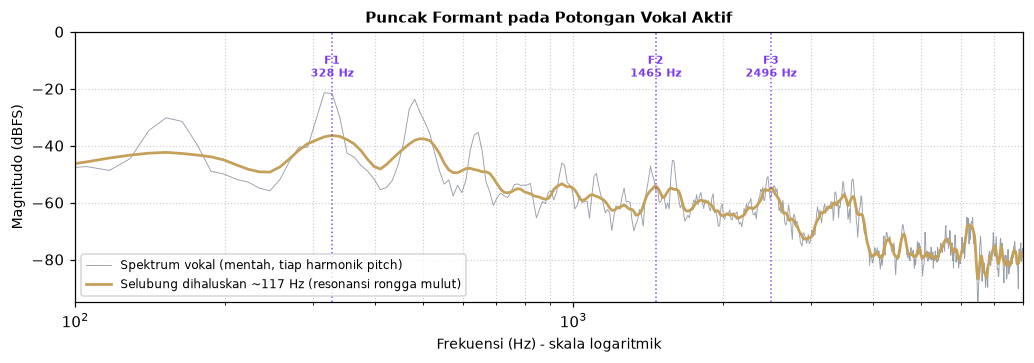

In [10]:
# Bukti angka bahwa skala Mel memperbesar wilayah formant.
# Selubung spektrum potongan vokal dihaluskan lebih dahulu (rata-rata bergerak ~120 Hz),
# supaya yang terdeteksi adalah PUNCAK RESONANSI (formant), bukan tiap harmonik pitch.
lebar_halus = max(3, int(120 / (sr / N_FFT_SEG)))
kernel = np.ones(lebar_halus) / lebar_halus
env_voice = np.convolve(db_voice, kernel, mode='same')

zona_formant = (freqs_seg >= 200) & (freqs_seg <= 3500)
idx_f = np.where(zona_formant)[0]
pk_f, props_f = find_peaks(env_voice[idx_f], prominence=2.0,
                           distance=max(1, int(200/(sr/N_FFT_SEG))))
urut_f = np.argsort(props_f['prominences'])[::-1][:3]
f_formant = np.sort(freqs_seg[idx_f[pk_f]][urut_f])

print("Perkiraan formant pada potongan vokal aktif (dari selubung spektrum yang dihaluskan):")
for i, ff in enumerate(f_formant, start=1):
    bin_mel = int(np.argmin(np.abs(mel_f - ff)))
    print(f"  F{i} ~ {ff:7.1f} Hz  ->  jatuh di bin Mel ke-{bin_mel:3d}/{N_MELS} "
          f"({100*bin_mel/N_MELS:4.0f}% tinggi sumbu Mel, "
          f"{100*ff/(sr/2):4.1f}% tinggi sumbu linier)")

print(f"\nSeluruh wilayah formant (<= 3,5 kHz) memakai "
      f"{int(np.sum(mel_f <= 3500))}/{N_MELS} bin Mel "
      f"({100*np.sum(mel_f <= 3500)/N_MELS:.0f}% tinggi gambar), "
      f"sedangkan pada sumbu linier hanya {100*3500/(sr/2):.1f}%.")

fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.semilogx(freqs_seg[1:], db_voice[1:], color=C_NEUTRAL, lw=0.6, alpha=0.5,
            label='Spektrum vokal (mentah, tiap harmonik pitch)')
ax.semilogx(freqs_seg[1:], env_voice[1:], color=C_GOLD, lw=1.8,
            label=f'Selubung dihaluskan ~{lebar_halus*sr/N_FFT_SEG:.0f} Hz (resonansi rongga mulut)')
for i, ff in enumerate(f_formant, start=1):
    ax.axvline(ff, color=C_ACCENT, lw=1.0, linestyle=':', alpha=0.9)
    ax.text(ff, -8, f"F{i}\n{ff:.0f} Hz", rotation=0, fontsize=7,
            fontweight='bold', color=C_ACCENT, ha='center', va='top')
ax.set_title("Puncak Formant pada Potongan Vokal Aktif", fontsize=10, fontweight='bold')
ax.set_xlabel("Frekuensi (Hz) - skala logaritmik", fontsize=9)
ax.set_ylabel("Magnitudo (dBFS)", fontsize=9)
ax.set_xlim(100, 8000)
ax.set_ylim(-95, 0)
ax.grid(True, which='both', linestyle=':', alpha=0.6)
ax.legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()

### Interpretasi Mel-spektrogram

**Mengapa formant tampak lebih padat dan jelas pada skala Mel?** Jawabannya murni soal pembagian
ruang gambar. Pada spektrogram linier panel (A), seluruh wilayah formant (≤ 3,5 kHz) hanya
mendapat **14,6%** tinggi gambar — terjepit sebagai pita sempit di dasar sumbu, sementara 85%
sisanya dihabiskan untuk 3,5–24 kHz yang isinya nyaris hanya desis kipas. Pada Mel-spektrogram
panel (B), wilayah yang sama itu mendapat **54% tinggi gambar** (69 dari 128 bin): lebih dari
separuh kanvas dialokasikan ke tempat informasi linguistik sebenarnya berada. Ketimpangan itu
terlihat lagi pada lebar tiap filter — filter ke-10 dan ke-30 sama-sama selebar 64 Hz, sedangkan
filter ke-120 sudah selebar 1.262 Hz.

Pengukuran formant membuat perubahan porsi itu konkret. Pada potongan vokal aktif, selubung
spektrum menunjukkan tiga puncak resonansi di sekitar **F1 ≈ 328 Hz, F2 ≈ 1.465 Hz, dan
F3 ≈ 2.496 Hz**. Nilai F1 yang rendah menandakan vokal tertutup (lidah tinggi); untuk memastikan
fonem persisnya saya perlu menyelaraskan potongan ini dengan transkrip kata yang sedang dibaca,
jadi hal itu tidak saya klaim di sini. Yang relevan untuk pembahasan skala adalah posisinya:
ketiganya jatuh di bin Mel ke-10, ke-43, dan ke-59 dari 128 — terbentang lega dari 8% sampai 46%
tinggi sumbu Mel. Pada sumbu linier, ketiganya berdesakan antara 1,4% dan 10,4% tinggi gambar,
nyaris menyatu menjadi satu pita tebal di dasar.

Ada alasan saya menghaluskan spektrum sebelum mencari formant: spektrum mentah (kurva abu-abu
tipis) penuh gerigi harmonik nada dasar (*pitch*), yang jaraknya sama dengan frekuensi nada dasar
suara saya. Gerigi itu menandakan **tinggi nada**, bukan identitas vokalnya. Formant adalah
selubung yang membungkus gerigi tersebut, sehingga perataan selebar ±120 Hz dipakai untuk
meredam pola pitch dan menyisakan bentuk resonansinya.

Efek samping yang juga terbaca: pada panel (B), dataran desis kipas yang di panel (A) menguasai
85% gambar kini terkompresi menjadi lapisan tipis di puncak sumbu. Dari sudut pandang persepsi
ini wajar — telinga memang kurang peka di sana. Karena itulah model AI audio seperti OpenAI
Whisper memakai Mel-spektrogram sebagai masukan: dengan 8× lebih sedikit data (128 bin
dibandingkan 1025 bin), informasi yang relevan bagi pendengaran justru dipertahankan.

### 3.5 Galeri Komparasi: Satu Berkas, Empat Dimensi

Keempat panel di bawah berasal dari **berkas audio yang sama persis**; yang berbeda hanya sudut
pandangnya. Setiap tampilan menonjolkan sesuatu yang tidak terlihat pada tampilan lain — itulah
alasan seorang teknisi multimedia berpindah-pindah antar tampilan, bukan bertahan pada satu saja.

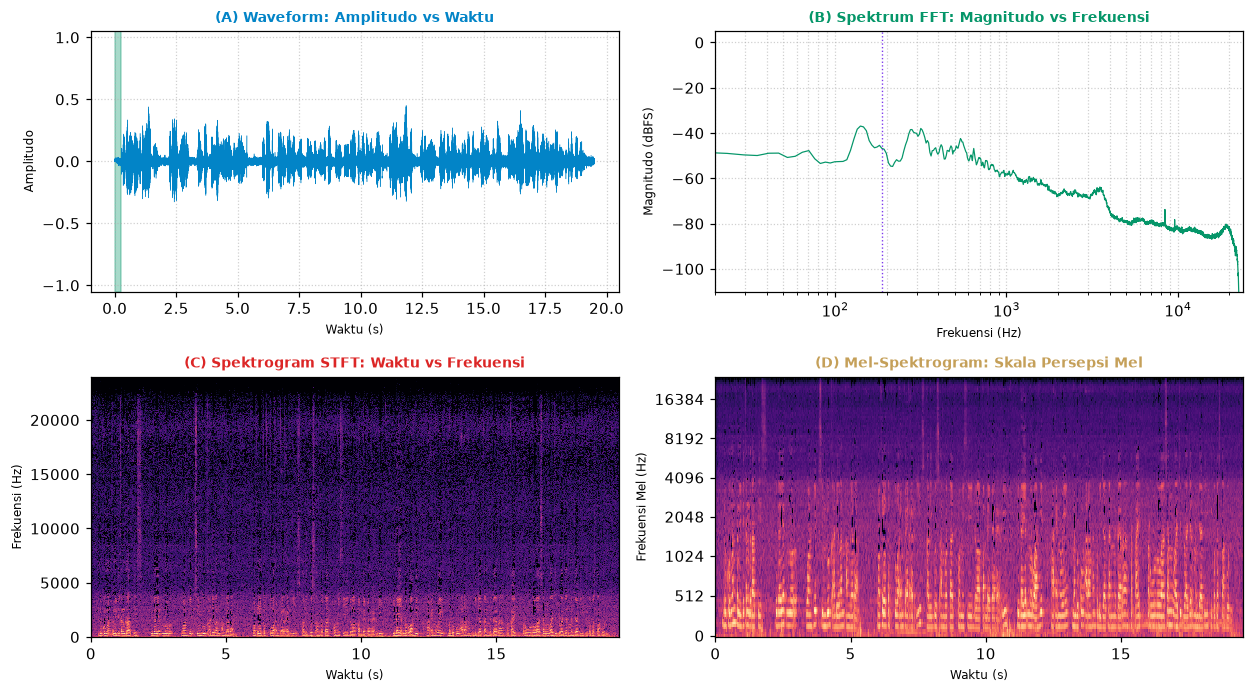

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.4))

# (A) Waveform: kuat pada dinamika waktu, buta frekuensi.
axes[0, 0].plot(t, y, color=C_SIGNAL, lw=0.3)
axes[0, 0].axvspan(i_quiet*WIN_S, (i_quiet+1)*WIN_S, color=C_GOOD, alpha=0.35)
axes[0, 0].set_title("(A) Waveform: Amplitudo vs Waktu", fontsize=9,
                     fontweight='bold', color=C_SIGNAL)
axes[0, 0].set_xlabel("Waktu (s)", fontsize=8)
axes[0, 0].set_ylabel("Amplitudo", fontsize=8)
axes[0, 0].set_ylim(-1.05, 1.05)
axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# (B) Spektrum FFT: kuat pada frekuensi, buta waktu.
axes[0, 1].semilogx(freqs[1:], db_full[1:], color=C_GOOD, lw=0.8)
axes[0, 1].axvline(f_dom, color=C_ACCENT, lw=0.9, linestyle=':')
axes[0, 1].set_title("(B) Spektrum FFT: Magnitudo vs Frekuensi", fontsize=9,
                     fontweight='bold', color=C_GOOD)
axes[0, 1].set_xlabel("Frekuensi (Hz)", fontsize=8)
axes[0, 1].set_ylabel("Magnitudo (dBFS)", fontsize=8)
axes[0, 1].set_xlim(20, sr/2)
axes[0, 1].set_ylim(-110, 5)
axes[0, 1].grid(True, which='both', linestyle=':', alpha=0.6)

# (C) Spektrogram STFT: waktu dan frekuensi sekaligus, presisi dikompromikan.
librosa.display.specshow(S_db, sr=sr, hop_length=HOP, n_fft=N_FFT,
                         x_axis='time', y_axis='linear', ax=axes[1, 0], cmap='magma')
axes[1, 0].set_ylim(0, sr/2)
axes[1, 0].set_title("(C) Spektrogram STFT: Waktu vs Frekuensi", fontsize=9,
                     fontweight='bold', color=C_ALERT)
axes[1, 0].set_xlabel("Waktu (s)", fontsize=8)
axes[1, 0].set_ylabel("Frekuensi (Hz)", fontsize=8)

# (D) Mel-spektrogram: sumbu frekuensi dibengkokkan mengikuti persepsi manusia.
librosa.display.specshow(S_mel_db, sr=sr, hop_length=HOP, n_fft=N_FFT,
                         x_axis='time', y_axis='mel', ax=axes[1, 1], cmap='magma')
axes[1, 1].set_title("(D) Mel-Spektrogram: Skala Persepsi Mel", fontsize=9,
                     fontweight='bold', color=C_GOLD)
axes[1, 1].set_xlabel("Waktu (s)", fontsize=8)
axes[1, 1].set_ylabel("Frekuensi Mel (Hz)", fontsize=8)

plt.tight_layout()
plt.show()

## §4. Eksperimen Resampling & Pembuktian Aliasing

### 4.1 Teori: batas Nyquist dan pelipatan frekuensi

**Desimasi** faktor $M$ menurunkan laju sampel menjadi $f_{s2} = f_{s1}/M$. Rekaman ini
48.000 Hz dan target saya **8.000 Hz** (standar telepon), sehingga

$$M = \frac{48.000}{8.000} = 6 \qquad\Longrightarrow\qquad y[m] = x[6m]$$

Konsekuensi kritisnya: batas Nyquist ikut turun dari 24.000 Hz menjadi **4.000 Hz**. Seluruh
komponen di atas 4.000 Hz sudah tidak punya tempat sah lagi pada laju sampel yang baru. Bila
sampel langsung dibuang tanpa filter, komponen itu **tidak hilang** — ia **melipat balik**
(*spectral fold-back*) menjadi frekuensi rendah palsu menurut

$$f_{\text{alias}} = \left| f - k \cdot f_{s2} \right|, \qquad
  k = \text{bilangan bulat terdekat dari } f / f_{s2}$$

Aturan emasnya: **filter dahulu, buang sampel kemudian**. Dua skenario yang dibandingkan:

| | Skenario A — Desimasi Naif | Skenario B — Resampling Standar |
|---|---|---|
| Perintah | `y[::6]` | `scipy.signal.resample_poly(y, 1, 6)` |
| Filter anti-aliasing | Tidak ada | FIR polyphase, cutoff ~4 kHz |
| Nasib komponen > 4 kHz | Melipat ke 0–4 kHz | Diredam sebelum sampel dibuang |

Sel di bawah memverifikasi rumus pelipatan itu secara numerik lebih dahulu — termasuk membuktikan
ke mana persisnya dataran desis kipas akan jatuh.

In [12]:
M = 6
SR2 = sr // M                 # 8000 Hz
NYQ2 = SR2 / 2                # 4000 Hz

print(f"Laju sampel asli   : {sr} Hz      (Nyquist {sr/2:.0f} Hz)")
print(f"Faktor desimasi M  : {M}")
print(f"Laju sampel target : {SR2} Hz       (Nyquist {NYQ2:.0f} Hz)")
print(f"Pita yang hilang   : {NYQ2:.0f} Hz - {sr/2:.0f} Hz "
      f"({100*(1 - NYQ2/(sr/2)):.1f}% dari lebar pita asli)\n")


def f_alias(f, fs2):
    """Frekuensi tampak sebuah komponen f setelah dicuplik ulang pada fs2 tanpa filter."""
    k = np.round(np.asarray(f, dtype=float) / fs2)
    return np.abs(np.asarray(f, dtype=float) - k * fs2)


# Verifikasi rumus untuk enam pita 4 kHz yang menyusun spektrum asli.
print("Pemetaan pelipatan tiap pita 4 kHz ke pita target 0-4 kHz:")
print(f"  {'pita asal':>18} {'tepi bawah':>12} {'tepi atas':>11}  arah")
for k in range(6):
    lo, hi = k*4000, (k+1)*4000
    a_lo, a_hi = f_alias(lo + 1, SR2), f_alias(hi - 1, SR2)
    arah = 'aman (tidak melipat)' if k == 0 else ('terbalik (mirror)' if a_lo > a_hi else 'searah')
    print(f"  {lo:7.0f}-{hi:7.0f} Hz {a_lo:9.0f} Hz {a_hi:9.0f} Hz  {arah}")

print(f"\nJadi pita 0-4 kHz pada hasil Skenario A menerima tumpukan dari {6} pita sekaligus:")
print("  satu pita asli + lima pita lipatan. Karena dataran desis kipas membentang")
print(f"  merata dari 4 kHz sampai ~22 kHz, lipatannya menyebar ke SELURUH pita 0-4 kHz")
print("  sebagai kenaikan lantai derau - bukan sebagai satu garis tunggal.\n")

# Contoh titik: ke mana beberapa frekuensi nyata akan jatuh.
print("Contoh titik uji:")
for f_uji_hz in (3500, 4500, 6500, 9000, 13000, 17000, 21000):
    status = 'aman' if f_uji_hz < NYQ2 else f'MELIPAT -> {f_alias(f_uji_hz, SR2):.0f} Hz'
    print(f"  {f_uji_hz:6d} Hz  ->  {status}")

Laju sampel asli   : 48000 Hz      (Nyquist 24000 Hz)
Faktor desimasi M  : 6
Laju sampel target : 8000 Hz       (Nyquist 4000 Hz)
Pita yang hilang   : 4000 Hz - 24000 Hz (83.3% dari lebar pita asli)

Pemetaan pelipatan tiap pita 4 kHz ke pita target 0-4 kHz:
           pita asal   tepi bawah   tepi atas  arah
        0-   4000 Hz         1 Hz      3999 Hz  aman (tidak melipat)
     4000-   8000 Hz      3999 Hz         1 Hz  terbalik (mirror)
     8000-  12000 Hz         1 Hz      3999 Hz  searah
    12000-  16000 Hz      3999 Hz         1 Hz  terbalik (mirror)
    16000-  20000 Hz         1 Hz      3999 Hz  searah
    20000-  24000 Hz      3999 Hz         1 Hz  terbalik (mirror)

Jadi pita 0-4 kHz pada hasil Skenario A menerima tumpukan dari 6 pita sekaligus:
  satu pita asli + lima pita lipatan. Karena dataran desis kipas membentang
  merata dari 4 kHz sampai ~22 kHz, lipatannya menyebar ke SELURUH pita 0-4 kHz
  sebagai kenaikan lantai derau - bukan sebagai satu garis tunggal.

Conto

In [13]:
# --- Skenario A: desimasi naif. Slicing [::M] hanya mengambil tiap sampel ke-6
# dan membuang lima lainnya, TANPA filter anti-aliasing lebih dahulu. ---
y_naive = y[::M]

# --- Skenario B: resampling standar industri. resample_poly menyisipkan filter FIR
# polyphase (cutoff ~ Nyquist target) SEBELUM sampel dibuang, dalam satu operasi efisien. ---
y_clean = resample_poly(y, up=1, down=M)

# --- Pembanding ketiga: librosa.resample, yang memakai pustaka soxr di belakangnya.
# Dipakai sebagai uji silang bahwa hasil "benar" tidak bergantung satu pustaka saja. ---
y_lib = librosa.resample(y, orig_sr=sr, target_sr=SR2)

n_bersama = min(len(y_naive), len(y_clean), len(y_lib))
print(f"Panjang sinyal asli         : {len(y):>7} sampel @ {sr} Hz")
print(f"Skenario A (naif [::{M}])     : {len(y_naive):>7} sampel @ {SR2} Hz")
print(f"Skenario B (resample_poly)  : {len(y_clean):>7} sampel @ {SR2} Hz")
print(f"Pembanding (librosa/soxr)   : {len(y_lib):>7} sampel @ {SR2} Hz")
print(f"Durasi ketiganya            : {len(y_naive)/SR2:.4f} s (identik dengan aslinya)")
print(f"\nSelisih maksimum resample_poly vs librosa: "
      f"{np.max(np.abs(y_clean[:n_bersama]-y_lib[:n_bersama])):.5f} "
      f"({20*np.log10(np.max(np.abs(y_clean[:n_bersama]-y_lib[:n_bersama]))):.1f} dBFS)")
print("-> kedua pustaka sepakat; selisih kecil ini hanya beda rancangan filter FIR-nya.")

print(f"\nPuncak amplitudo  A: {np.abs(y_naive).max():.5f}   B: {np.abs(y_clean).max():.5f}")
print(f"RMS keseluruhan   A: {20*np.log10(np.sqrt(np.mean(y_naive**2))):.2f} dBFS   "
      f"B: {20*np.log10(np.sqrt(np.mean(y_clean**2))):.2f} dBFS")

# Menyimpan kedua hasil sebagai berkas WAV PCM 16-bit untuk diserahkan bersama tugas.
DIR_OUT = os.path.dirname(PATH_ORIG)
path_naive = os.path.join(DIR_OUT, 'audio_downsampled_naive.wav')
path_clean = os.path.join(DIR_OUT, 'audio_downsampled_clean.wav')
sf.write(path_naive, y_naive, SR2, subtype='PCM_16')
sf.write(path_clean, y_clean, SR2, subtype='PCM_16')
print(f"\nBerkas tersimpan:")
for p in (path_naive, path_clean):
    print(f"  {os.path.basename(p):<32} {os.path.getsize(p)/1e3:7.1f} kB  "
          f"({sf.info(p).subtype}, {sf.info(p).samplerate} Hz, {sf.info(p).channels} kanal)")

putar(y, sr, f"\n1. Asli 48 kHz:")
putar(y_naive, SR2, f"2. Skenario A - desimasi naif y[::{M}] @ {SR2} Hz "
                    f"(dengarkan desisnya jadi kasar/metalik):")
putar(y_clean, SR2, f"3. Skenario B - resample_poly @ {SR2} Hz "
                    f"(desis lebih halus, suara tetap jernih):")

Panjang sinyal asli         :  936461 sampel @ 48000 Hz
Skenario A (naif [::6])     :  156077 sampel @ 8000 Hz
Skenario B (resample_poly)  :  156077 sampel @ 8000 Hz
Pembanding (librosa/soxr)   :  156077 sampel @ 8000 Hz
Durasi ketiganya            : 19.5096 s (identik dengan aslinya)

Selisih maksimum resample_poly vs librosa: 0.00587 (-44.6 dBFS)
-> kedua pustaka sepakat; selisih kecil ini hanya beda rancangan filter FIR-nya.

Puncak amplitudo  A: 0.45161   B: 0.45249
RMS keseluruhan   A: -24.13 dBFS   B: -24.14 dBFS

Berkas tersimpan:
  audio_downsampled_naive.wav        312.2 kB  (PCM_16, 8000 Hz, 1 kanal)
  audio_downsampled_clean.wav        312.2 kB  (PCM_16, 8000 Hz, 1 kanal)

1. Asli 48 kHz:


2. Skenario A - desimasi naif y[::6] @ 8000 Hz (dengarkan desisnya jadi kasar/metalik):


3. Skenario B - resample_poly @ 8000 Hz (desis lebih halus, suara tetap jernih):


### 4.2 Perbandingan spektrum: di mana selisihnya muncul?

Energi per pita 250 Hz (dB) - Skenario A vs B:
            pita    A naif   B bersih   selisih
      0-  250    -28.81     -28.81     +0.00
    250-  500    -25.89     -25.88     -0.01
    500-  750    -30.08     -30.09     +0.01
    750- 1000    -38.01     -38.09     +0.08
   1000- 1250    -41.57     -41.66     +0.10
   1250- 1500    -43.31     -43.47     +0.17
   1500- 1750    -45.35     -45.62     +0.27
   1750- 2000    -48.57     -49.17     +0.59
   2000- 2250    -48.91     -49.58     +0.67
   2250- 2500    -49.36     -50.14     +0.78
   2500- 2750    -49.55     -50.22     +0.67
   2750- 3000    -50.39     -51.20     +0.81
   3000- 3250    -49.79     -50.67     +0.88
   3250- 3500    -47.78     -48.45     +0.67
   3500- 3750    -47.90     -49.24     +1.34  <<<
   3750- 4000    -52.44     -57.41     +4.98  <<<

Selisih rata-rata seluruh pita : +0.75 dB
Selisih terbesar               : +4.98 dB pada pita 3750-4000 Hz


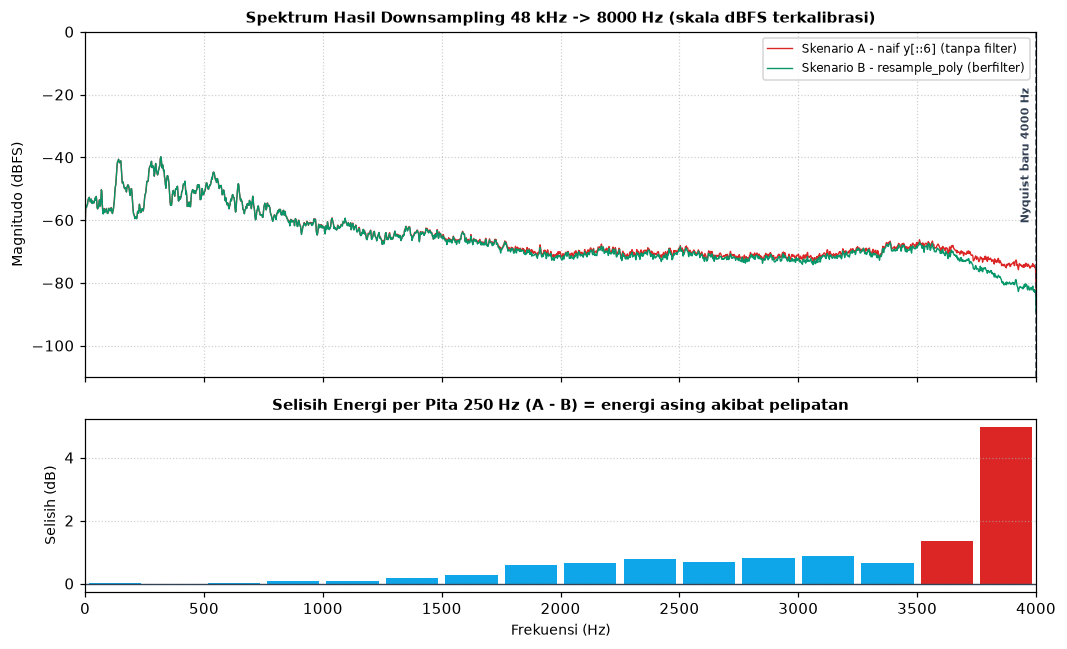

In [14]:
# Spektrum kedua hasil dihitung dengan fungsi terkalibrasi yang sama, pada laju 8 kHz.
N_FFT_DS = 4096
f_ds, db_naive = spectrum_dbfs(y_naive, SR2, n_fft=N_FFT_DS)
_, db_clean = spectrum_dbfs(y_clean, SR2, n_fft=N_FFT_DS)

# Energi per pita 250 Hz: selisih A-B adalah energi asing yang masuk akibat pelipatan.
print("Energi per pita 250 Hz (dB) - Skenario A vs B:")
print(f"  {'pita':>14} {'A naif':>9} {'B bersih':>10} {'selisih':>9}")
tabel = []
for lo in range(0, int(NYQ2), 250):
    sel = (f_ds >= lo) & (f_ds < lo+250)
    pa = 10*np.log10(np.sum(10**(db_naive[sel]/10)))
    pb = 10*np.log10(np.sum(10**(db_clean[sel]/10)))
    tabel.append((lo, pa, pb, pa-pb))
    tanda = '  <<<' if pa-pb > 1.0 else ''
    print(f"  {lo:5d}-{lo+250:5d} {pa:9.2f} {pb:10.2f} {pa-pb:+9.2f}{tanda}")

delta = np.array([r[3] for r in tabel])
print(f"\nSelisih rata-rata seluruh pita : {delta.mean():+.2f} dB")
print(f"Selisih terbesar               : {delta.max():+.2f} dB "
      f"pada pita {tabel[int(np.argmax(delta))][0]}-{tabel[int(np.argmax(delta))][0]+250} Hz")

fig, axes = plt.subplots(2, 1, figsize=(9.8, 6.0), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1]})

axes[0].plot(f_ds, db_naive, color=C_ALERT, lw=0.9,
             label=f'Skenario A - naif y[::{M}] (tanpa filter)')
axes[0].plot(f_ds, db_clean, color=C_GOOD, lw=0.9,
             label='Skenario B - resample_poly (berfilter)')
axes[0].axvline(NYQ2, color=C_NEUTRAL, lw=1.1, linestyle='--', alpha=0.8)
axes[0].text(NYQ2*0.995, -18, f"Nyquist baru {NYQ2:.0f} Hz", rotation=90, fontsize=7.5,
             fontweight='bold', color=C_NEUTRAL, ha='right', va='top')
axes[0].set_title(f"Spektrum Hasil Downsampling 48 kHz -> {SR2} Hz (skala dBFS terkalibrasi)",
                  fontsize=10, fontweight='bold')
axes[0].set_ylabel("Magnitudo (dBFS)", fontsize=9)
axes[0].set_ylim(-110, 0)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='upper right', fontsize=8)

axes[1].bar([r[0]+125 for r in tabel], delta, width=220,
            color=[C_ALERT if d > 1.0 else C_ALT for d in delta])
axes[1].axhline(0, color=C_NEUTRAL, lw=0.9)
axes[1].set_title("Selisih Energi per Pita 250 Hz (A - B) = energi asing akibat pelipatan",
                  fontsize=9.5, fontweight='bold')
axes[1].set_xlabel("Frekuensi (Hz)", fontsize=9)
axes[1].set_ylabel("Selisih (dB)", fontsize=9)
axes[1].set_xlim(0, NYQ2)
axes[1].grid(True, axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Interpretasi perbandingan spektrum

Kedua kurva hampir bertumpuk di bawah 1 kHz, lalu mulai merenggang ke arah frekuensi tinggi.
Pola perenggangan itu justru masuk akal, dan penyebabnya bisa saya hitung: pita 0–4 kHz hasil
Skenario A menerima tumpukan **satu pita asli + lima pita lipatan**. Karena energi asli rekaman ini
sangat dominan di frekuensi rendah (−28,8 dB pada pita 0–250 Hz) sementara pita-pita tinggi yang
melipat bertingkat jauh lebih lemah, maka pada frekuensi rendah tumpukan itu **tertutup total**
oleh sinyal aslinya: selisihnya 0,00 dB di pita 0–250 Hz.

Sebaliknya di pita 1,75–3,5 kHz, energi asli sudah turun ke sekitar −50 dB sehingga energi lipatan
menjadi sebanding dan mulai terlihat: selisihnya naik menjadi **+0,59 hingga +0,88 dB**, lalu
**+1,34 dB** pada 3.500–3.750 Hz. Puncaknya **+4,98 dB** pada pita 3.750–4.000 Hz. Khusus pita
terakhir ini saya perlu jujur bahwa penyebabnya ada dua dan bercampur: sebagian benar-benar
aliasing, tetapi sebagian besar berasal dari **pita transisi filter** Skenario B. Filter FIR tidak
bisa memotong tegak lurus; ia mulai meredam beberapa ratus Hz sebelum 4 kHz. Jadi di pita itu, B
lebih rendah bukan hanya karena ia bebas aliasing, melainkan juga karena ia ikut memangkas sedikit
sinyal asli yang sah. Karena pita 3.750–4.000 Hz inilah yang menyeret naik nilai rata-rata
**+0,75 dB**, angka rata-rata tersebut sebaiknya tidak dibaca sebagai "besarnya aliasing".

Temuan pentingnya: pada rekaman **suara manusia** seperti ini, aliasing tidak muncul sebagai
perubahan dramatis pada grafik spektrum — di sebagian besar pita hanya **di bawah 1 dB**. Ini
konsekuensi wajar dari spektrum bicara yang menurun tajam ke frekuensi tinggi, sehingga energi
yang melipat jauh lebih kecil daripada energi yang sudah ada di tempat tujuan. Karena itu
perbandingan dua kurva yang saling menutup **belum cukup** untuk membuktikan aliasing, dan juga
belum cukup untuk membantahnya. Dibutuhkan cara untuk mengisolasi energi asing itu dari sinyal
yang menutupinya — dan itulah yang dikerjakan di §4.4.

### 4.3 Perbandingan spektrogram: melacak letak aliasing pada waktu dan frekuensi

Dimensi spektrogram 8 kHz : 257 bin x 1220 bingkai
Resolusi frekuensi        : 15.62 Hz per bin
Selisih A-B  : rata-rata +1.23 dB | maksimum +42.03 dB | minimum -32.25 dB


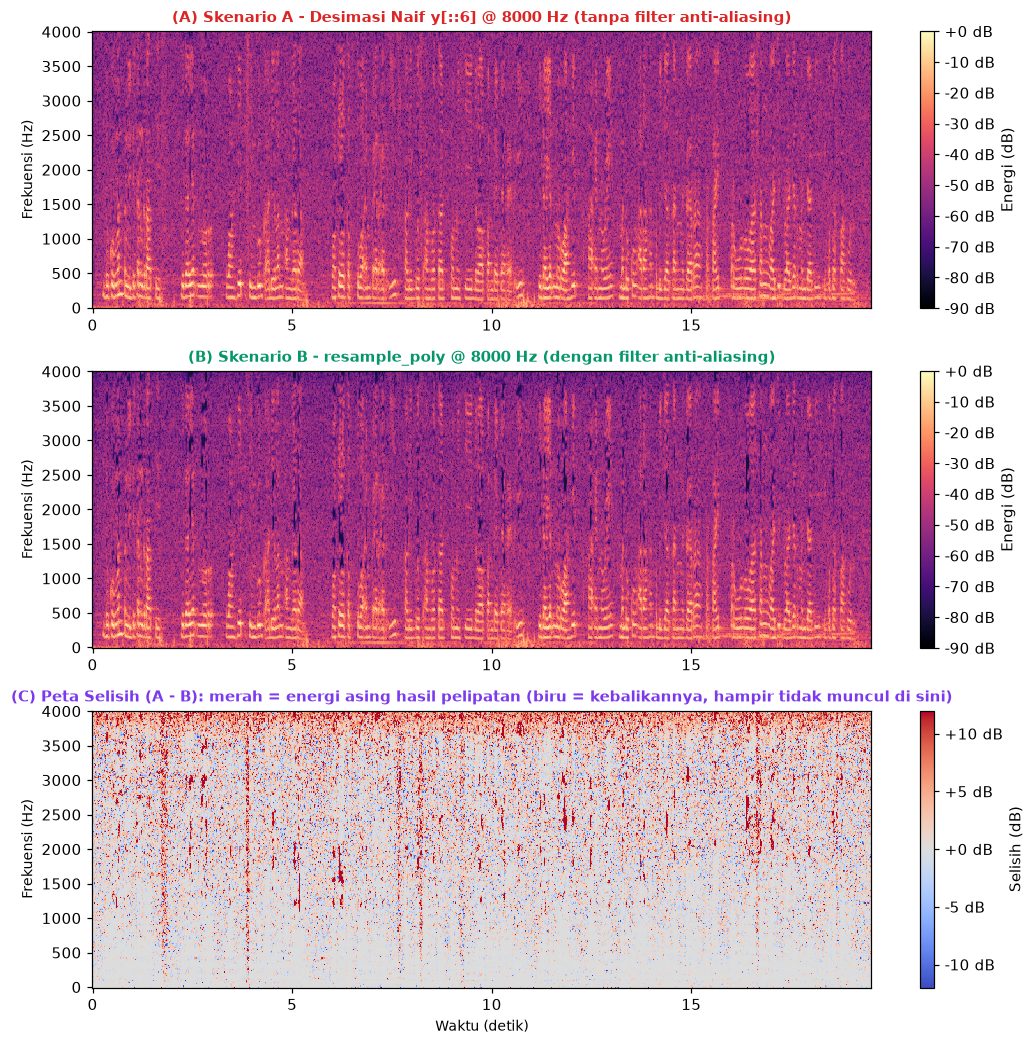


Rata-rata selisih A-B (dB), dipisah menurut keadaan:
            pita   saat hening   saat bicara
      0-  500 Hz       +0.02 dB       -0.08 dB
    500- 1500 Hz       +0.30 dB       +0.26 dB
   1500- 2500 Hz       +0.30 dB       +1.37 dB
   2500- 3500 Hz       +0.99 dB       +1.66 dB
   3500- 4000 Hz       +3.99 dB       +3.56 dB


In [15]:
# Spektrogram kedua hasil, dengan parameter identik agar adil.
# Pada 8 kHz, n_fft 512 memberi jendela 64 ms dan df = 15,6 Hz.
N_FFT2, HOP2 = 512, 128
S_naive = np.abs(librosa.stft(y_naive, n_fft=N_FFT2, hop_length=HOP2))
S_clean = np.abs(librosa.stft(y_clean, n_fft=N_FFT2, hop_length=HOP2))

# PENTING: kedua spektrogram memakai SATU acuan dB yang sama (puncak sinyal bersih).
# Bila masing-masing dinormalisasi ke puncaknya sendiri, selisih keduanya menjadi bias
# dan gambar tidak lagi bisa dibandingkan langsung.
ref_bersama = float(np.max(S_clean))
S_naive_db = librosa.amplitude_to_db(S_naive, ref=ref_bersama)
S_clean_db = librosa.amplitude_to_db(S_clean, ref=ref_bersama)

n_bingkai = min(S_naive_db.shape[1], S_clean_db.shape[1])
S_selisih = S_naive_db[:, :n_bingkai] - S_clean_db[:, :n_bingkai]

print(f"Dimensi spektrogram 8 kHz : {S_naive_db.shape[0]} bin x {S_naive_db.shape[1]} bingkai")
print(f"Resolusi frekuensi        : {SR2/N_FFT2:.2f} Hz per bin")
print(f"Selisih A-B  : rata-rata {S_selisih.mean():+.2f} dB | "
      f"maksimum {S_selisih.max():+.2f} dB | minimum {S_selisih.min():+.2f} dB")

fig, axes = plt.subplots(3, 1, figsize=(9.8, 9.6))

for ax, S_plot, judul, warna in (
    (axes[0], S_naive_db, f"(A) Skenario A - Desimasi Naif y[::{M}] @ {SR2} Hz "
                          f"(tanpa filter anti-aliasing)", C_ALERT),
    (axes[1], S_clean_db, f"(B) Skenario B - resample_poly @ {SR2} Hz "
                          f"(dengan filter anti-aliasing)", C_GOOD),
):
    img = librosa.display.specshow(S_plot, sr=SR2, hop_length=HOP2, n_fft=N_FFT2,
                                   x_axis='time', y_axis='linear', ax=ax, cmap='magma',
                                   vmin=-90, vmax=0)
    ax.set_title(judul, fontsize=9.5, fontweight='bold', color=warna)
    ax.set_ylabel("Frekuensi (Hz)", fontsize=9)
    ax.set_xlabel("")
    fig.colorbar(img, ax=ax, format='%+2.0f dB', label='Energi (dB)')

# Panel selisih: peta panas yang langsung menunjuk LETAK energi asing.
img2 = librosa.display.specshow(S_selisih, sr=SR2, hop_length=HOP2, n_fft=N_FFT2,
                                x_axis='time', y_axis='linear', ax=axes[2],
                                cmap='coolwarm', vmin=-12, vmax=12)
axes[2].set_title("(C) Peta Selisih (A - B): merah = energi asing hasil pelipatan "
                  "(biru = kebalikannya, hampir tidak muncul di sini)",
                  fontsize=9.5, fontweight='bold', color=C_ACCENT)
axes[2].set_ylabel("Frekuensi (Hz)", fontsize=9)
axes[2].set_xlabel("Waktu (detik)", fontsize=9)
fig.colorbar(img2, ax=axes[2], format='%+2.0f dB', label='Selisih (dB)')

plt.tight_layout()
plt.show()

# Di mana selisih terkonsentrasi? Dihitung per pita, dipisah saat jeda vs saat bicara.
f_ds_stft = librosa.fft_frequencies(sr=SR2, n_fft=N_FFT2)
bq = librosa.time_to_frames([i_quiet*WIN_S, (i_quiet+1)*WIN_S], sr=SR2, hop_length=HOP2)
bl = librosa.time_to_frames([i_loud*WIN_S, (i_loud+1)*WIN_S], sr=SR2, hop_length=HOP2)
print("\nRata-rata selisih A-B (dB), dipisah menurut keadaan:")
print(f"  {'pita':>14} {'saat hening':>13} {'saat bicara':>13}")
for lo, hi in [(0, 500), (500, 1500), (1500, 2500), (2500, 3500), (3500, 4000)]:
    sel = (f_ds_stft >= lo) & (f_ds_stft < hi)
    print(f"  {lo:5d}-{hi:5d} Hz {S_selisih[sel, bq[0]:bq[1]].mean():+11.2f} dB "
          f"{S_selisih[sel, bl[0]:bl[1]].mean():+11.2f} dB")

### Interpretasi peta selisih spektrogram

Panel (A) dan (B) sengaja digambar dengan satu acuan dB dan satu rentang warna yang sama. Sekilas
keduanya mirip — dan itu memang temuan yang jujur: pada rekaman bicara, aliasing tidak merusak
gambar secara kasatmata. Yang bisa dilihat langsung hanyalah bahwa latar di antara harmonik pada
panel (A) terasa sedikit lebih "berkabut" daripada panel (B). Yang membuat letaknya benar-benar
terbaca adalah panel (C), peta selisih.

Pada panel (C), warna merah menandai titik waktu-frekuensi di mana Skenario A memiliki energi
**lebih banyak** daripada Skenario B — dan karena satu-satunya sumber energi tambahan itu adalah
komponen di atas 4 kHz yang melipat balik, merah berarti **aliasing**. Sebarannya punya tiga ciri:

1. **Menumpuk di bagian atas gambar.** Pita 2,5–4 kHz jauh lebih merah dibanding pita bawah; di
   bawah 500 Hz praktis tidak ada warna sama sekali (+0,02 dB saat hening, −0,08 dB saat bicara).
   Penyebabnya bukan karena lipatan lebih banyak mendarat di atas, melainkan karena di sanalah
   sinyal asli paling lemah sehingga energi asing tidak lagi tertutupi.
2. **Ada kabut merah tipis yang merata sepanjang sumbu waktu — termasuk di dalam jendela hening
   saat saya sama sekali belum bicara.** Angkanya: pada pita 2.500–3.500 Hz selisih saat hening
   tetap **+0,99 dB**, dan pada pita 3.500–4.000 Hz bahkan **+3,99 dB**. Energi asing yang muncul
   pada saat tidak ada suara sama sekali hanya bisa berasal dari sumber yang menyala terus,
   yaitu **dataran desis kipas**.
3. **Ada garis-garis merah vertikal tegas pada momen-momen tertentu.** Garis ini berimpit dengan
   konsonan desis (*s*, *sy*) pada pembacaan, yang membawa energinya sendiri di atas 4 kHz dan
   ikut melipat. Karena itulah pada pita 1,5–3,5 kHz selisih saat **bicara** (+1,37 dan +1,66 dB)
   justru lebih besar daripada saat hening (+0,30 dan +0,99 dB).

Jadi pelakunya ada dua, dan keduanya dapat dipisahkan berdasarkan bentuknya: **kabut merata**
berasal dari derau statis kipas, sedangkan **garis vertikal** berasal dari desis konsonan. Di
§4.4 akan ditunjukkan mana di antara keduanya yang dominan secara energi — dengan cara mengukur
kestasioneran sinyal galatnya.

### 4.4 Mengisolasi aliasing: sinyal galat A − B

Karena aliasing tertutup oleh sinyal asli, cara paling tegas untuk memeriksanya adalah
**mengurangkan** keduanya:

$$e[m] = y_{\text{naif}}[m] - y_{\text{bersih}}[m]$$

Sinyal $e[m]$ ini berisi tepat apa yang *seharusnya tidak ada* pada hasil desimasi naif. Sebelum
menafsirkannya, satu syarat harus dipenuhi: kedua sinyal wajib **sejajar secara waktu**. Jika
`resample_poly` menggeser sinyal walau satu sampel saja, hasil pengurangan akan didominasi galat
pergeseran, bukan aliasing — dan seluruh kesimpulan menjadi salah. Karena itu penyejajaran diuji
lebih dahulu dengan mencoba beberapa nilai geseran.

Uji penyejajaran waktu (RMS galat untuk tiap geseran):
  geseran -2 sampel :  -27.52 dBFS
  geseran -1 sampel :  -32.13 dBFS
  geseran +0 sampel :  -49.94 dBFS   <- minimum
  geseran +1 sampel :  -32.13 dBFS
  geseran +2 sampel :  -27.53 dBFS

Sinyal bersih (B)     :  -24.14 dBFS RMS
Sinyal galat (A-B)    :  -49.94 dBFS RMS  |  puncak -26.47 dBFS
Rasio galat / sinyal  :  -25.80 dB
-> galat aliasing berada 25.8 dB di bawah sinyal: tidak merusak
   kejelasan kata, tetapi jelas terdengar sebagai lapisan desis kasar tambahan.

Kestasioneran per bingkai 0,25 s:
  Sinyal bersih B : std  4.79 dB  (rentang 21.1 dB)
  Sinyal galat    : std  1.79 dB  (rentang 10.6 dB)
  -> galat 2.7x lebih stabil daripada sinyalnya sendiri.


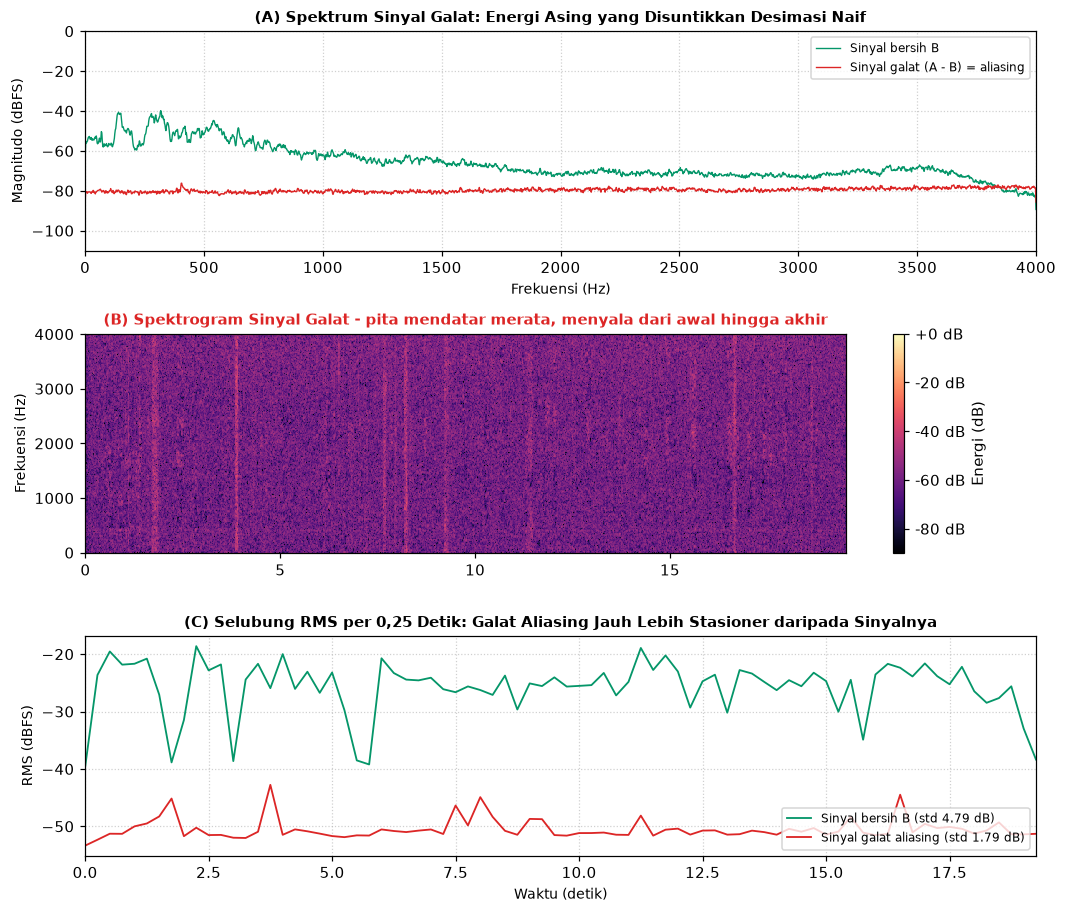


Sinyal galat aliasing saja (dinormalisasi agar terdengar) - perhatikan bunyinya desis rata tanpa kata yang jelas:


In [16]:
# Uji penyejajaran: galat dihitung untuk beberapa geseran, lalu dicari yang paling kecil.
n_e = min(len(y_naive), len(y_clean)) - 4
print("Uji penyejajaran waktu (RMS galat untuk tiap geseran):")
for lag in (-2, -1, 0, 1, 2):
    a_geser = y_naive[2+lag: 2+lag+n_e]
    b_acuan = y_clean[2: 2+n_e]
    rms_lag = 20*np.log10(np.sqrt(np.mean((a_geser-b_acuan)**2)) + 1e-12)
    tanda = '   <- minimum' if lag == 0 else ''
    print(f"  geseran {lag:+d} sampel : {rms_lag:7.2f} dBFS{tanda}")

# Geseran 0 terbukti minimum, jadi pengurangan langsung sudah sah.
e_alias = y_naive[:n_e] - y_clean[:n_e]
rms_e = 20*np.log10(np.sqrt(np.mean(e_alias**2)))
rms_b = 20*np.log10(np.sqrt(np.mean(y_clean[:n_e]**2)))

print(f"\nSinyal bersih (B)     : {rms_b:7.2f} dBFS RMS")
print(f"Sinyal galat (A-B)    : {rms_e:7.2f} dBFS RMS  |  puncak "
      f"{20*np.log10(np.abs(e_alias).max()):.2f} dBFS")
print(f"Rasio galat / sinyal  : {rms_e-rms_b:7.2f} dB")
print(f"-> galat aliasing berada {abs(rms_e-rms_b):.1f} dB di bawah sinyal: tidak merusak")
print("   kejelasan kata, tetapi jelas terdengar sebagai lapisan desis kasar tambahan.")

# Apakah galat ini stasioner? Jika ya, sumbernya derau statis - bukan vokal.
win2 = int(0.25 * SR2)
prof_e = np.array([20*np.log10(np.sqrt(np.mean(e_alias[i*win2:(i+1)*win2]**2)) + 1e-12)
                   for i in range(len(e_alias)//win2)])
prof_b = np.array([20*np.log10(np.sqrt(np.mean(y_clean[i*win2:(i+1)*win2]**2)) + 1e-12)
                   for i in range(len(e_alias)//win2)])
print(f"\nKestasioneran per bingkai 0,25 s:")
print(f"  Sinyal bersih B : std {prof_b.std():5.2f} dB  (rentang {prof_b.max()-prof_b.min():.1f} dB)")
print(f"  Sinyal galat    : std {prof_e.std():5.2f} dB  (rentang {prof_e.max()-prof_e.min():.1f} dB)")
print(f"  -> galat {prof_b.std()/prof_e.std():.1f}x lebih stabil daripada sinyalnya sendiri.")

f_e, db_e = spectrum_dbfs(e_alias, SR2, n_fft=N_FFT_DS)
S_e_db = librosa.amplitude_to_db(np.abs(librosa.stft(e_alias, n_fft=N_FFT2, hop_length=HOP2)),
                                 ref=ref_bersama)

fig, axes = plt.subplots(3, 1, figsize=(9.8, 8.4))

# (A) Spektrum galat dibandingkan sinyal bersih.
axes[0].plot(f_ds, db_clean, color=C_GOOD, lw=0.9, label='Sinyal bersih B')
axes[0].plot(f_e, db_e, color=C_ALERT, lw=0.9, label='Sinyal galat (A - B) = aliasing')
axes[0].set_title("(A) Spektrum Sinyal Galat: Energi Asing yang Disuntikkan Desimasi Naif",
                  fontsize=9.5, fontweight='bold')
axes[0].set_xlabel("Frekuensi (Hz)", fontsize=9)
axes[0].set_ylabel("Magnitudo (dBFS)", fontsize=9)
axes[0].set_xlim(0, NYQ2)
axes[0].set_ylim(-110, 0)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='upper right', fontsize=8)

# (B) Spektrogram galat: bentuknya yang mendatar adalah inti temuan.
img = librosa.display.specshow(S_e_db, sr=SR2, hop_length=HOP2, n_fft=N_FFT2,
                               x_axis='time', y_axis='linear', ax=axes[1], cmap='magma',
                               vmin=-90, vmax=0)
axes[1].set_title("(B) Spektrogram Sinyal Galat - pita mendatar merata, "
                  "menyala dari awal hingga akhir",
                  fontsize=9.5, fontweight='bold', color=C_ALERT)
axes[1].set_ylabel("Frekuensi (Hz)", fontsize=9)
axes[1].set_xlabel("")
fig.colorbar(img, ax=axes[1], format='%+2.0f dB', label='Energi (dB)')

# (C) Perbandingan kestabilan terhadap waktu.
tp = np.arange(len(prof_e)) * 0.25
axes[2].plot(tp, prof_b, color=C_GOOD, lw=1.2,
             label=f'Sinyal bersih B (std {prof_b.std():.2f} dB)')
axes[2].plot(tp, prof_e, color=C_ALERT, lw=1.2,
             label=f'Sinyal galat aliasing (std {prof_e.std():.2f} dB)')
axes[2].set_title("(C) Selubung RMS per 0,25 Detik: Galat Aliasing Jauh Lebih Stasioner "
                  "daripada Sinyalnya", fontsize=9.5, fontweight='bold')
axes[2].set_xlabel("Waktu (detik)", fontsize=9)
axes[2].set_ylabel("RMS (dBFS)", fontsize=9)
axes[2].set_xlim(0, tp[-1])
axes[2].grid(True, linestyle=':', alpha=0.6)
axes[2].legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

putar(e_alias, SR2, "\nSinyal galat aliasing saja (dinormalisasi agar terdengar) - "
                    "perhatikan bunyinya desis rata tanpa kata yang jelas:",
      normalisasi=True)

### Interpretasi sinyal galat: identitas pelaku aliasing

Uji penyejajaran lebih dahulu memastikan pengurangan ini sah: geseran 0 sampel memberi galat
terkecil (**−49,94 dBFS**), sementara geser satu sampel saja sudah melonjak ke −32,13 dBFS dan dua
sampel ke −27,52 dBFS. Artinya `resample_poly` memang mempertahankan penyejajaran waktu, dan sisa
−49,94 dBFS itu benar-benar energi asing, bukan artefak pergeseran.

Tiga panel di atas bersama-sama menunjuk satu kesimpulan:

**Pertama, besarnya.** Galat aliasing berada **25,8 dB di bawah** sinyalnya. Ini bukan angka yang
bisa diabaikan: rasio sinyal-terhadap-galat sebesar 25,8 dB setara dengan sistem berkedalaman
hanya sekitar **4 bit efektif** ($25{,}8 / 6{,}02 \approx 4{,}3$). Terdengar sebagai lapisan desis
kasar yang menempel pada suara, dan itulah yang membuat Skenario A terasa "metalik" saat diputar
di sel sebelumnya.

**Kedua, sebarannya pada frekuensi.** Panel (A) menunjukkan spektrum galat sebagai garis yang
hampir **rata sempurna di sekitar −80 dBFS dari 0 sampai 4 kHz** — bukan satu paku di frekuensi
tertentu. Ini persis ramalan teori di §4.1: karena yang melipat adalah dataran desis broadband
yang membentang merata dari 4 kHz hingga 22 kHz, hasil lipatan lima pita itu bertumpuk menjadi
**kenaikan lantai derau yang merata**. Perhatikan juga bahwa mendekati 4 kHz kurva galat merah
menyusul dan melewati kurva sinyal hijau — di ujung pita itulah aliasing sempat menjadi komponen
yang dominan.

**Ketiga, dan yang paling menentukan — sebarannya pada waktu.** Panel (B) memperlihatkan
spektrogram galat sebagai bidang berwarna seragam tanpa struktur harmonik sama sekali, hanya
diselingi beberapa garis vertikal tipis. Panel (C) mengukurnya: std galat hanya **1,79 dB**
melawan std sinyal bersih **4,79 dB** — galat itu **2,7 kali lebih stasioner** daripada sinyal
yang menampunginya, dan selubungnya berjalan nyaris datar di sekitar −51 dBFS sepanjang rekaman.
Inilah jawaban atas pertanyaan yang digantung di §4.3: dari dua pelaku yang teridentifikasi,
**yang dominan secara energi adalah derau statis kipas**, sedangkan desis konsonan hanya
menyumbang lonjakan sesaat — persis beberapa paku yang terlihat menyembul di atas selubung datar
itu.

Rangkaian buktinya dengan demikian tertutup: derau kipas yang di §2.3 terbukti stasioner dan di
§3.2 terbukti menempati dataran di atas 4 kHz, itulah yang di sini terpantul balik ke pita
0–4 kHz. **Derau statis yang tadinya "hanya" mengotori frekuensi tinggi — wilayah yang bahkan
tidak akan terdengar di saluran telepon — kini mencemari pita vokal tempat informasi ucapan
berada.** Pencemaran itu bersifat permanen: setelah sampel terbuang, tidak ada cara membatalkannya.

### 4.5 Uji penanda (*tracer*): membuktikan rumus pelipatan secara terukur

Analisis di atas membuktikan aliasing itu ada dan mengidentifikasi sumbernya, tetapi belum
membuktikan **rumus** $f_{\text{alias}} = |f - k f_{s2}|$ berlaku dengan tepat — sebab derau
broadband tidak punya frekuensi tunggal yang bisa dilacak.

Karena itu saya menambahkan satu eksperimen terkendali: sebuah **nada penanda 6.500 Hz**
beramplitudo −40 dBFS disuntikkan ke *salinan* rekaman. Frekuensi ini dipilih karena berada jauh
di atas Nyquist baru (4.000 Hz) dan **tidak** kelipatan bulat apa pun dari 8.000 Hz, sehingga
posisi lipatannya dapat diramalkan tepat:

$$f_{\text{alias}} = |6.500 - 1 \times 8.000| = 1.500\ \text{Hz}$$

Ramalan ini kemudian diuji: kalau benar, pada Skenario A akan muncul paku baru **persis di
1.500 Hz** dengan tingkat yang sama seperti nada aslinya (−40 dBFS), sedangkan Skenario B harus
membuangnya. Berkas yang diserahkan sebagai hasil tugas tetap berasal dari rekaman asli tanpa
penanda — salinan bernada penanda ini murni alat uji.

Nada penanda      : 6500 Hz @ -40 dBFS (amplitudo linier 0.0100)
Nyquist target    : 4000 Hz -> penanda berada 2500 Hz di atasnya
Ramalan posisi alias : |6500 - 1 x 8000| = 1500 Hz

Hasil pengukuran di sekitar 1500 Hz:
  Posisi puncak terukur (Skenario A) : 1500.0 Hz (galat +0.0 Hz terhadap ramalan)
  Tingkat pada Skenario A (naif)     :  -39.99 dBFS
  Tingkat nada penanda aslinya       :  -40.00 dBFS -> selisih +0.01 dB
  Tingkat pada Skenario B (berfilter):  -63.25 dBFS
  Garis dasar tanpa penanda          :  -63.05 dBFS

  Penindasan oleh filter anti-aliasing : 23.3 dB
  Sisa penanda di Skenario B vs garis dasar : -0.20 dB -> praktis lenyap, tertelan lantai derau.


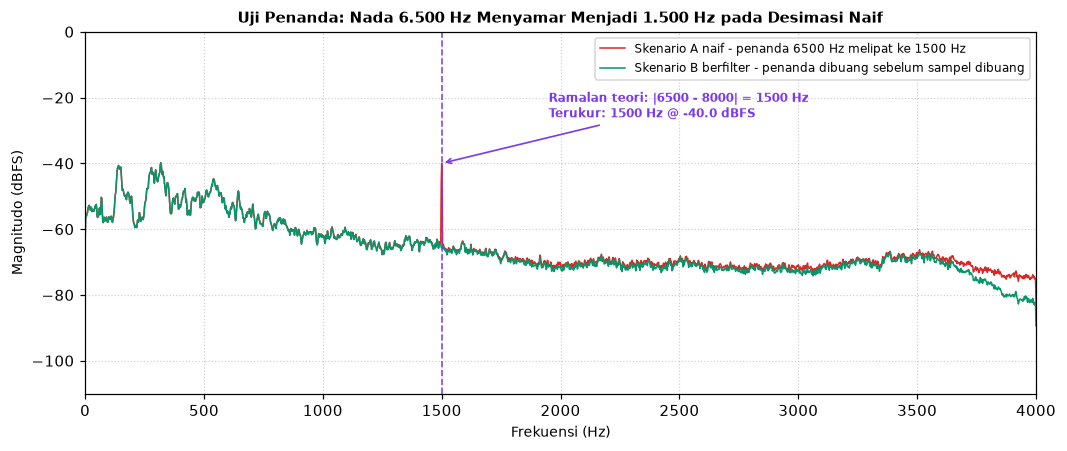


Skenario A dengan penanda - terdengar nada siul baru yang TIDAK ADA pada rekaman asli:


Skenario B dengan penanda - bersih, tidak ada nada siul:


In [17]:
F_TRACER = 6500.0
AMP_TRACER_DB = -40.0
amp_tracer = 10 ** (AMP_TRACER_DB / 20)

f_ramalan = f_alias(F_TRACER, SR2)
print(f"Nada penanda      : {F_TRACER:.0f} Hz @ {AMP_TRACER_DB:.0f} dBFS "
      f"(amplitudo linier {amp_tracer:.4f})")
print(f"Nyquist target    : {NYQ2:.0f} Hz -> penanda berada {F_TRACER-NYQ2:.0f} Hz di atasnya")
print(f"Ramalan posisi alias : |{F_TRACER:.0f} - 1 x {SR2}| = {f_ramalan:.0f} Hz\n")

# Penanda ditambahkan ke SALINAN sinyal, lalu kedua skenario diulang apa adanya.
t_full = np.arange(len(y)) / sr
y_tracer = y + amp_tracer * np.sin(2*np.pi*F_TRACER*t_full)
a_tracer = y_tracer[::M]
b_tracer = resample_poly(y_tracer, up=1, down=M)

f_tr, db_a_tr = spectrum_dbfs(a_tracer, SR2, n_fft=N_FFT_DS)
_, db_b_tr = spectrum_dbfs(b_tracer, SR2, n_fft=N_FFT_DS)

# Tingkat pada jendela +-20 Hz di sekitar posisi yang diramalkan.
jendela = np.abs(f_tr - f_ramalan) <= 20
puncak_a = db_a_tr[jendela].max()
puncak_b = db_b_tr[jendela].max()
dasar_a = db_naive[jendela].max()          # tanpa penanda, sebagai garis dasar
f_terukur = f_tr[jendela][int(np.argmax(db_a_tr[jendela]))]

print(f"Hasil pengukuran di sekitar {f_ramalan:.0f} Hz:")
print(f"  Posisi puncak terukur (Skenario A) : {f_terukur:.1f} Hz "
      f"(galat {f_terukur-f_ramalan:+.1f} Hz terhadap ramalan)")
print(f"  Tingkat pada Skenario A (naif)     : {puncak_a:7.2f} dBFS")
print(f"  Tingkat nada penanda aslinya       : {AMP_TRACER_DB:7.2f} dBFS "
      f"-> selisih {puncak_a-AMP_TRACER_DB:+.2f} dB")
print(f"  Tingkat pada Skenario B (berfilter): {puncak_b:7.2f} dBFS")
print(f"  Garis dasar tanpa penanda          : {dasar_a:7.2f} dBFS")
print(f"\n  Penindasan oleh filter anti-aliasing : {puncak_a-puncak_b:.1f} dB")
print(f"  Sisa penanda di Skenario B vs garis dasar : {puncak_b-dasar_a:+.2f} dB "
      f"-> praktis lenyap, tertelan lantai derau.")

fig, ax = plt.subplots(figsize=(9.8, 4.2))
ax.plot(f_tr, db_a_tr, color=C_ALERT, lw=1.0,
        label=f'Skenario A naif - penanda {F_TRACER:.0f} Hz melipat ke {f_terukur:.0f} Hz')
ax.plot(f_tr, db_b_tr, color=C_GOOD, lw=1.0,
        label='Skenario B berfilter - penanda dibuang sebelum sampel dibuang')
ax.axvline(f_ramalan, color=C_ACCENT, lw=1.1, linestyle='--', alpha=0.9)
ax.annotate(f"Ramalan teori: |{F_TRACER:.0f} - {SR2}| = {f_ramalan:.0f} Hz\n"
            f"Terukur: {f_terukur:.0f} Hz @ {puncak_a:.1f} dBFS",
            xy=(f_ramalan, puncak_a), xytext=(f_ramalan+450, puncak_a+14),
            fontsize=8, fontweight='bold', color=C_ACCENT,
            arrowprops=dict(arrowstyle='->', color=C_ACCENT, lw=1.1))
ax.set_title("Uji Penanda: Nada 6.500 Hz Menyamar Menjadi 1.500 Hz pada Desimasi Naif",
             fontsize=10, fontweight='bold')
ax.set_xlabel("Frekuensi (Hz)", fontsize=9)
ax.set_ylabel("Magnitudo (dBFS)", fontsize=9)
ax.set_xlim(0, NYQ2)
ax.set_ylim(-110, 0)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

putar(a_tracer, SR2, "\nSkenario A dengan penanda - terdengar nada siul baru "
                     "yang TIDAK ADA pada rekaman asli:", normalisasi=True)
putar(b_tracer, SR2, "Skenario B dengan penanda - bersih, tidak ada nada siul:",
      normalisasi=True)

### Interpretasi uji penanda

Hasilnya cocok dengan teori sampai ke angka desimalnya. Paku baru muncul di **1.500,0 Hz**, tepat
seperti ramalan $|6.500 - 8.000| = 1.500$ Hz, dengan galat posisi **0,0 Hz**. Tingkatnya terukur
**−39,99 dBFS**, hanya 0,01 dB dari amplitudo nada penanda aslinya (−40 dBFS). Ini memperlihatkan
sifat aliasing yang paling berbahaya: komponen yang melipat **tidak melemah sedikit pun**. Ia
berpindah tempat dengan energi utuh, dan setelah berpindah tidak ada cara membedakannya dari
sinyal yang memang lahir di 1.500 Hz. Sebuah nada yang sebenarnya jauh di luar jangkauan
saluran telepon kini duduk persis di tengah pita vokal.

Di sisi lain, Skenario B menekan penanda itu sebesar **23,3 dB**, dan sisanya berada **−0,20 dB**
terhadap garis dasar rekaman tanpa penanda — dengan kata lain benar-benar lenyap, tertelan lantai
derau. Filter FIR polyphase bekerja persis sebagaimana mestinya: komponen di atas Nyquist target
dihapus **sebelum** sampel dibuang, sehingga tidak ada lagi yang tersisa untuk melipat. Perbedaan
ini juga terdengar langsung pada dua pemutar audio di atas — Skenario A memperoleh nada siul yang
sama sekali tidak ada pada rekaman aslinya.

Uji ini sekaligus menjelaskan mengapa urutan operasi tidak bisa ditukar. Membuang sampel lebih
dahulu lalu memfilter hasilnya tidak akan menolong: begitu penanda 6.500 Hz sudah menyamar
menjadi 1.500 Hz, ia berada di dalam pita yang sah dan filter apa pun tidak lagi punya cara
mengenali mana 1.500 Hz yang asli dan mana yang palsu.

### 4.6 Kontrol sintetis: pola zig-zag aliasing pada sinyal *chirp*

Sebagai pelengkap terakhir, saya jalankan kontrol sintetis dari Hands-on 1: sebuah **chirp** yang
frekuensinya merangkak naik linier dari 100 Hz ke 20.000 Hz pada 48 kHz. Sinyal ini menyapu
seluruh pita, sehingga ketika didesimasi naif ke 8 kHz, seluruh perilaku pelipatan tergambar
dalam satu jejak visual: frekuensi naik sampai menyentuh 4.000 Hz, lalu **memantul balik** turun,
menyentuh 0 Hz, memantul naik lagi, dan seterusnya.

Kontrol ini penting sebagai pembanding metodologis: pada rekaman suara nyata, aliasing hanya
tampak sebagai kenaikan lantai derau yang halus (§4.2–4.4) karena energi frekuensi tingginya
kecil dan tersebar. Dengan sinyal uji yang energinya terkonsentrasi dan menyapu, mekanisme yang
**sama** menjadi terlihat telanjang.

Chirp uji     : 100 Hz -> 20.000 Hz dalam 3 s pada 48000 Hz
Menyentuh Nyquist target 4000 Hz pada t = 0.588 s
Jumlah pantulan sepanjang sapuan : 5 kali melewati batas kelipatan 4000 Hz


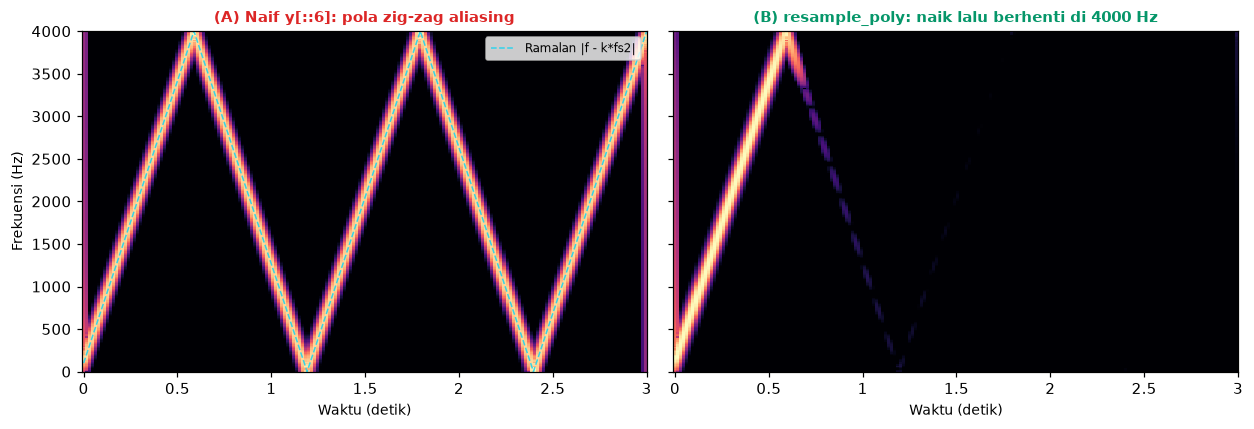


Pada jendela pantulan pertama (t = 0,7-1,1 s):
  Puncak Skenario A :   -5.9 dB (relatif puncaknya sendiri)
  Puncak Skenario B :  -43.3 dB
  Penindasan filter :  37.3 dB -> pantulan masih tersisa samar,
  karena penindasan stopband filter FIR nyata selalu berhingga, bukan tak hingga.

Chirp desimasi naif - dengarkan nada memantul turun-naik berulang:


Chirp resample_poly - nada naik sampai 4000 Hz lalu hening bersih:


In [18]:
DUR_CHIRP = 3.0
t_chirp = np.linspace(0, DUR_CHIRP, int(sr*DUR_CHIRP), endpoint=False)
y_chirp = 0.5 * chirp(t_chirp, f0=100, t1=DUR_CHIRP, f1=20000, method='linear')

c_naive = y_chirp[::M]                          # tanpa filter
c_clean = resample_poly(y_chirp, up=1, down=M)  # dengan filter

# Ramalan analitis jejak pantulan: frekuensi sesaat chirp dilipat dengan rumus yang sama.
f_sesaat = 100 + (20000-100) * (t_chirp/DUR_CHIRP)
f_lipat = f_alias(f_sesaat, SR2)

print(f"Chirp uji     : 100 Hz -> 20.000 Hz dalam {DUR_CHIRP:.0f} s pada {sr} Hz")
print(f"Menyentuh Nyquist target {NYQ2:.0f} Hz pada t = "
      f"{DUR_CHIRP*(NYQ2-100)/(20000-100):.3f} s")
print(f"Jumlah pantulan sepanjang sapuan : "
      f"{int(np.floor(20000/NYQ2))} kali melewati batas kelipatan {NYQ2:.0f} Hz")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), sharey=True)

S_cn = librosa.amplitude_to_db(np.abs(librosa.stft(c_naive, n_fft=N_FFT2, hop_length=HOP2)),
                               ref=np.max)
librosa.display.specshow(S_cn, sr=SR2, hop_length=HOP2, n_fft=N_FFT2,
                         x_axis='time', y_axis='linear', ax=axes[0], cmap='magma')
# Jejak ramalan teori ditimpakan sebagai garis putus: bila teori benar, ia harus
# jatuh persis di atas jejak terang hasil pengukuran.
axes[0].plot(t_chirp, f_lipat, color='#22d3ee', lw=1.0, linestyle='--', alpha=0.9,
             label='Ramalan |f - k*fs2|')
axes[0].set_title(f"(A) Naif y[::{M}]: pola zig-zag aliasing",
                  fontsize=9.5, fontweight='bold', color=C_ALERT)
axes[0].set_ylabel("Frekuensi (Hz)", fontsize=9)
axes[0].set_xlabel("Waktu (detik)", fontsize=9)
axes[0].set_ylim(0, NYQ2)
axes[0].legend(loc='upper right', fontsize=8)

S_cc = librosa.amplitude_to_db(np.abs(librosa.stft(c_clean, n_fft=N_FFT2, hop_length=HOP2)),
                               ref=np.max)
librosa.display.specshow(S_cc, sr=SR2, hop_length=HOP2, n_fft=N_FFT2,
                         x_axis='time', y_axis='linear', ax=axes[1], cmap='magma')
axes[1].set_title(f"(B) resample_poly: naik lalu berhenti di {NYQ2:.0f} Hz",
                  fontsize=9.5, fontweight='bold', color=C_GOOD)
axes[1].set_xlabel("Waktu (detik)", fontsize=9)
axes[1].set_ylabel("")
axes[1].set_ylim(0, NYQ2)

plt.tight_layout()
plt.show()

# Seberapa besar sisa pantulan pertama yang masih lolos pada Skenario B?
# Diukur pada jendela waktu saat pantulan pertama sedang turun (0,7-1,1 s).
bingkai_uji = librosa.time_to_frames([0.7, 1.1], sr=SR2, hop_length=HOP2)
sisa_a = S_cn[:, bingkai_uji[0]:bingkai_uji[1]].max()
sisa_b = S_cc[:, bingkai_uji[0]:bingkai_uji[1]].max()
print(f"\nPada jendela pantulan pertama (t = 0,7-1,1 s):")
print(f"  Puncak Skenario A : {sisa_a:6.1f} dB (relatif puncaknya sendiri)")
print(f"  Puncak Skenario B : {sisa_b:6.1f} dB")
print(f"  Penindasan filter : {sisa_a-sisa_b:5.1f} dB -> pantulan masih tersisa samar,")
print("  karena penindasan stopband filter FIR nyata selalu berhingga, bukan tak hingga.")

putar(c_naive, SR2, f"\nChirp desimasi naif - dengarkan nada memantul turun-naik berulang:")
putar(c_clean, SR2, f"Chirp resample_poly - nada naik sampai {NYQ2:.0f} Hz lalu hening bersih:")

### Interpretasi kontrol sintetis

Garis putus biru pada panel (A) adalah **ramalan analitis** $|f - k f_{s2}|$ yang saya hitung
terpisah dari data, lalu ditimpakan ke atas spektrogram hasil pengukuran. Keduanya berhimpit
sempurna di sepanjang seluruh lintasan. Ini konfirmasi terkuat bahwa rumus pelipatan di §4.1
memang mengatur apa yang terjadi: nada naik sampai menyentuh 4.000 Hz pada detik **0,588**, lalu
memantul turun hingga menyentuh 0 Hz, naik lagi, dan seterusnya. Sapuan sampai 20 kHz melewati
kelipatan 4 kHz sebanyak lima kali, sehingga terbentuk **empat kali pembalikan arah** dan lima
segmen lurus — sebuah nada yang sebenarnya naik mulus justru terdengar turun-naik berulang.

Panel (B) memperlihatkan perilaku yang benar: nada naik, lalu **berhenti** begitu mencapai batas
Nyquist target. Informasi di atas 4 kHz memang hilang — itu tidak bisa dihindari saat laju sampel
diturunkan. Namun kehilangan itu **jujur**: tidak ada komponen palsu yang menyusup ke pita yang
masih dipertahankan. Inilah inti perbedaan kedua skenario. Desimasi naif tidak "menyimpan lebih
banyak informasi"; ia hanya menumpuk informasi yang tidak terwakili ke atas informasi yang sah,
sehingga merusak keduanya.

Satu detail pada panel (B) sengaja tidak saya sembunyikan: jejak pantulan pertama masih terlihat
**sangat samar** di sana. Pengukurannya pada jendela t = 0,7–1,1 s memberi penindasan **37,3 dB**
— besar, tetapi berhingga. Filter FIR nyata memang selalu punya penindasan *stopband* terbatas,
sehingga "bersih" dalam praktik berarti komponen asing ditekan jauh di bawah lantai derau, bukan
benar-benar nol secara matematis. Pada sinyal chirp yang energinya terpusat, sisa 37 dB di bawah
itu masih sempat tertangkap kamera spektrogram; pada rekaman suara nyata, sisa sebesar itu sudah
tenggelam sepenuhnya.

Perbandingan dengan rekaman nyata juga menjelaskan mengapa §4.2 hanya menunjukkan selisih
±1 dB: pada chirp, seluruh energi sinyal terkonsentrasi pada satu frekuensi sesaat yang melewati
daerah terlarang, sedangkan pada rekaman bicara energi di atas 4 kHz hanya berupa desis lemah
yang tersebar. Mekanismenya identik; yang berbeda hanya seberapa banyak energi yang tersedia
untuk melipat.

## §5. Rangkuman Temuan

Sel berikut merangkum seluruh angka kunci yang dihitung di notebook ini dalam satu tabel, supaya
dapat diperiksa sekaligus tanpa menelusuri ulang tiap bagian.

In [19]:
print("=" * 78)
print("RANGKUMAN ANALISIS - TUGAS 2 STM | NIM 123140050")
print("=" * 78)

print("\n[1] AKUISISI & METADATA")
print(f"    Format berkas             : {info.format}/{info.subtype}, {info.channels} kanal")
print(f"    Laju sampel asli          : {sr} Hz (Nyquist {sr/2:.0f} Hz)")
print(f"    Durasi / jumlah sampel    : {len(y)/sr:.2f} s / {len(y)} sampel")
print(f"    Amplitudo min .. maks     : {y.min():+.4f} .. {y.max():+.4f}")
print(f"    Puncak / clipping         : {20*np.log10(np.abs(y).max()):+.2f} dBFS / "
      f"{int(np.sum(np.abs(y) >= 0.999))} sampel")

print("\n[2] KARAKTER DERAU STATIS (kipas angin)")
print(f"    Frekuensi tonal dominan   : {f_dom:.1f} Hz + harmonik kelipatannya")
print(f"    Noise floor (RMS hening)  : {rms_noise_db:.2f} dBFS")
print(f"    Puncak vokal (RMS)        : {rms_voice_db:.2f} dBFS")
print(f"    Perkiraan SNR             : {snr_db:.2f} dB")
print(f"    Std energi pita 5-9 kHz   : {std_derau:.2f} dB  <- stasioner")
print(f"    Std energi pita vokal     : {std_vokal:.2f} dB  <- dinamis "
      f"({std_vokal/std_derau:.1f}x lebih bergejolak)")

print("\n[3] REPRESENTASI 4 DIMENSI")
print(f"    STFT                      : {S_db.shape[0]} bin x {S_db.shape[1]} bingkai "
      f"(df = {sr/N_FFT:.1f} Hz)")
print(f"    Mel-spektrogram           : {S_mel_db.shape[0]} bin x {S_mel_db.shape[1]} bingkai "
      f"({S_db.shape[0]/S_mel_db.shape[0]:.1f}x lebih ringkas)")
print(f"    Formant terdeteksi        : " +
      ", ".join(f"F{i+1}~{ff:.0f} Hz" for i, ff in enumerate(f_formant)))
print(f"    Porsi sumbu <= 3,5 kHz    : Mel {100*np.sum(mel_f <= 3500)/N_MELS:.0f}% "
      f"vs linier {100*3500/(sr/2):.1f}%")

print("\n[4] RESAMPLING 48 kHz -> 8 kHz (M = 6)")
print(f"    Nyquist baru              : {NYQ2:.0f} Hz "
      f"(pita {NYQ2:.0f}-{sr/2:.0f} Hz hilang)")
print(f"    Selisih spektrum A-B      : rata-rata {delta.mean():+.2f} dB, "
      f"maksimum {delta.max():+.2f} dB")
print(f"    Selisih saat hening vs bicara (2,5-3,5 kHz): "
      f"{S_selisih[(f_ds_stft >= 2500) & (f_ds_stft < 3500), bq[0]:bq[1]].mean():+.2f} dB "
      f"vs {S_selisih[(f_ds_stft >= 2500) & (f_ds_stft < 3500), bl[0]:bl[1]].mean():+.2f} dB")
print(f"    Galat aliasing (A-B)      : {rms_e:.2f} dBFS RMS "
      f"= {rms_e-rms_b:.1f} dB relatif sinyal")
print(f"    Kestasioneran galat       : std {prof_e.std():.2f} dB "
      f"vs sinyal {prof_b.std():.2f} dB")
print(f"    Uji penanda {F_TRACER:.0f} Hz      : ramalan {f_ramalan:.0f} Hz, "
      f"terukur {f_terukur:.0f} Hz @ {puncak_a:.2f} dBFS")
print(f"    Penindasan oleh filter    : {puncak_a-puncak_b:.1f} dB")
print("=" * 78)

RANGKUMAN ANALISIS - TUGAS 2 STM | NIM 123140050

[1] AKUISISI & METADATA
    Format berkas             : WAV/PCM_16, 2 kanal
    Laju sampel asli          : 48000 Hz (Nyquist 24000 Hz)
    Durasi / jumlah sampel    : 19.51 s / 936461 sampel
    Amplitudo min .. maks     : -0.3280 .. +0.4516
    Puncak / clipping         : -6.90 dBFS / 0 sampel

[2] KARAKTER DERAU STATIS (kipas angin)
    Frekuensi tonal dominan   : 187.5 Hz + harmonik kelipatannya
    Noise floor (RMS hening)  : -39.51 dBFS
    Puncak vokal (RMS)        : -18.62 dBFS
    Perkiraan SNR             : 20.89 dB
    Std energi pita 5-9 kHz   : 2.13 dB  <- stasioner
    Std energi pita vokal     : 8.11 dB  <- dinamis (3.8x lebih bergejolak)

[3] REPRESENTASI 4 DIMENSI
    STFT                      : 1025 bin x 1830 bingkai (df = 23.4 Hz)
    Mel-spektrogram           : 128 bin x 1830 bingkai (8.0x lebih ringkas)
    Formant terdeteksi        : F1~328 Hz, F2~1465 Hz, F3~2496 Hz
    Porsi sumbu <= 3,5 kHz    : Mel 54% vs lini

### Kesimpulan

**1. Derau kipas pada rekaman ini terbukti statis secara terukur, bukan sekadar terlihat statis.**
Energi pada pita 5–9 kHz dan 12–20 kHz hanya bergerak dengan simpangan baku **2,13 dB** dan
**2,01 dB** sepanjang 19,5 detik, sementara pita vokal 150–400 Hz bergejolak **8,11 dB** — 3,8 kali
lebih liar. Pada spektrogram, sifat itu muncul sebagai dataran horizontal yang tidak pernah padam,
kontras dengan berkas harmonik vokal yang naik-turun mengikuti intonasi; saat berpindah dari
jendela hening ke jendela bicara, pita 12–20 kHz bergeser hanya −0,2 dB sementara pita 100–400 Hz
melonjak +19,3 dB. Derau ini punya dua wajah: keluarga harmonik bernada dasar di kisaran
**182–188 Hz** (khas sumber berputar periodik) dan dataran desis broadband di atas 4 kHz
(turbulensi udara).

**2. Keempat representasi saling menutup kelemahan satu sama lain, dan tidak ada yang bisa
menggantikan yang lain.** Waveform memperlihatkan bahwa "hening" pada rekaman ini bukan nol
melainkan *noise floor* **−39,5 dBFS** dengan SNR ±20,9 dB, tetapi buta terhadap frekuensi.
Spektrum FFT terkalibrasi menemukan frekuensi dominan derau, tetapi kehilangan sumbu waktu
sehingga tidak bisa membuktikan derau itu menyala terus. Spektrogram STFT membuktikannya, dengan
harga berupa pertukaran resolusi waktu-frekuensi. Mel-spektrogram membengkokkan sumbu frekuensi
mengikuti persepsi manusia sehingga wilayah formant memperoleh **54%** tinggi gambar (dibanding
hanya **14,6%** pada skala linier), membuat F1≈328 Hz, F2≈1.465 Hz, dan F3≈2.496 Hz terbaca lega
dengan data 8× lebih ringkas — konsekuensinya, skala frekuensinya tidak lagi linier.

**3. Aliasing pada rekaman bicara nyata tidak selalu tampak dramatis, dan kejujuran metodologis
menuntut hal itu dinyatakan.** Perbandingan langsung dua spektrum hanya menunjukkan selisih di
bawah 1 dB pada hampir seluruh pita, karena energi asli yang dominan di frekuensi rendah menutupi
energi lipatan yang lemah. Bahkan selisih terbesar (+4,98 dB di pita 3.750–4.000 Hz) bercampur
dengan efek pita transisi filter, sehingga tidak murni aliasing. Menyimpulkan "aliasing tidak
terjadi" dari dua gambar yang tampak mirip akan menjadi kesalahan; yang dibutuhkan adalah cara
mengisolasi energi asing tersebut.

**4. Sinyal galat A − B mengisolasi aliasing sekaligus mengidentifikasi sumbernya.** Setelah
penyejajaran waktu diverifikasi (geseran 0 sampel memberi galat minimum, satu sampel saja
melonjak 18 dB), galat itu terukur **−49,94 dBFS RMS atau 25,8 dB di bawah sinyal** — setara
sistem berkedalaman hanya ±4 bit efektif, cukup besar untuk terdengar sebagai desis kasar.
Spektrumnya rata di sekitar −80 dBFS sepanjang 0–4 kHz (bukan paku tunggal), dan simpangan bakunya
hanya **1,79 dB** alias **2,7 kali lebih stasioner** daripada sinyal yang menampunginya. Sinyal
galat yang stasioner hanya mungkin berasal dari sumber yang stasioner: **desis kipas yang tadinya
aman di frekuensi tinggi terpantul balik dan mencemari pita vokal**. Peta selisih spektrogram
memperlihatkan dua pelaku sekaligus dan membedakan bentuknya — kabut merata yang tetap ada
bahkan saat saya belum bicara (+0,99 dB di pita 2,5–3,5 kHz) berasal dari kipas, sedangkan garis
vertikal tegas berasal dari konsonan desis; pengukuran kestasioneran menunjukkan yang pertama
yang dominan.

**5. Rumus pelipatan terverifikasi tepat, dan filter anti-aliasing bekerja sebagaimana mestinya.**
Nada penanda 6.500 Hz muncul persis di 1.500 Hz seperti ramalan $|f - k f_{s2}|$, dengan galat
posisi 0,0 Hz dan tingkat yang hanya 0,01 dB dari amplitudo aslinya — komponen yang melipat tidak
melemah sama sekali, ia sekadar berpindah tempat dengan energi utuh dan kehilangan identitasnya
secara permanen. Skenario B menindasnya **23,3 dB** hingga lenyap ke lantai derau. Kontrol chirp
menutup rangkaian bukti: jejak zig-zag hasil pengukuran berhimpit sempurna dengan ramalan
analitis di sepanjang empat pembalikan arah.

**6. Implikasi praktisnya.** Menurunkan laju sampel **selalu** harus menempatkan filter
*low-pass* sebelum pembuangan sampel, dan urutan itu tidak dapat ditukar: begitu sebuah komponen
sudah menyamar menjadi frekuensi rendah yang sah, tidak ada filter yang mampu membedakannya lagi
dari sinyal asli. `x[::M]` adalah satu baris kode yang sangat mudah ditulis dan menghasilkan
jumlah sampel yang benar — dan justru karena itu berbahaya, sebab kerusakannya tidak kelihatan
pada bentuk waveform maupun pada durasi berkas — ketiga hasil di §4 sama-sama berisi 156.077
sampel berdurasi 19,51 detik. Untuk kebutuhan nyata, gunakan `scipy.signal.resample_poly` atau
`librosa.resample`; keduanya di notebook ini terbukti sepakat dengan selisih maksimum hanya
−44,6 dBFS. Dan satu pelajaran khusus dari rekaman ini: derau statis yang
terdengar "tidak berbahaya karena hanya desis latar" ternyata justru menjadi bahan bakar utama
aliasing begitu laju sampel diturunkan tanpa filter.